# Tower Bay Landsat Mosaics — True Colour, False Colour, Full & Masked

This notebook visualises **Tower Bay, southeast Tasmania** using the statewide Landsat image mosaics supplied by the **Institute for Marine and Antarctic Studies (IMAS), University of Tasmania**.

The source dataset is:

**Multi-decadal coverage of giant kelp (*Macrocystis pyrifera*) in Tasmania derived from satellite imagery**

The dataset was produced to investigate long-term changes in the **surface canopy of giant kelp around the Tasmanian coastline** using Landsat satellite imagery.

The notebook uses the supplementary archive:

> **`Landsat_statewide_mosaics.zip` — Landsat statewide image mosaics used in analysis**

### Official sources

- **IMAS metadata catalogue:**  
  https://metadata.imas.utas.edu.au/geonetwork/srv/eng/catalog.search#/metadata/029a5df5-04da-4c64-a73d-d15f1201965d
- **Dataset DOI:**  
  https://doi.org/10.25959/SX8Y-AK04
- **Direct statewide mosaic download:**  
  https://data.imas.utas.edu.au/attachments/029a5df5-04da-4c64-a73d-d15f1201965d/Landsat_statewide_mosaics.zip

**Dataset citation:** Butler, C. L., Lucieer, V., Johnson, C., & Wotherspoon, S. (2025). *Multi-decadal coverage of giant kelp (Macrocystis pyrifera) in Tasmania derived from satellite imagery* [Data set]. Institute for Marine and Antarctic Studies. https://doi.org/10.25959/SX8Y-AK04


## 1. About the satellite dataset

This is **not a general high-resolution satellite basemap**. It is a research dataset created specifically for monitoring **giant kelp (*Macrocystis pyrifera*) surface canopy** around Tasmania.

### Spatial and temporal coverage

According to the IMAS metadata:

- Landsat imagery was collected for the Tasmanian coastline from **1986–2015**.
- The statewide analysis covers **1987–2015** and groups imagery into **nine multi-year periods**.
- A separate, higher temporal-resolution dataset covers **24 specific Tasmanian coastal locations** using available cloud-free images from **1986–2015**.
- The statewide mosaics were constructed from **90 Landsat scenes**, primarily acquired from **July to December**, when giant-kelp canopy development is generally strongest.
- Landsat **TM, ETM+ and OLI** imagery was used.
- Spatial resolution is approximately **30 m per pixel**.
- Landsat has an approximately **16-day revisit cycle**, but cloud cover means usable images are less frequent.

### Why Landsat can detect giant kelp

Floating giant-kelp canopy behaves spectrally more like vegetation than open seawater:

- photosynthetic vegetation and kelp reflect strongly in the **near-infrared (NIR)**;
- seawater absorbs most incoming NIR radiation.

This contrast allows surface kelp canopy to be separated from surrounding water using multispectral imagery. The IMAS analysis used **NDVI (Normalised Difference Vegetation Index)** and a threshold-based classification to identify pixels interpreted as containing floating giant-kelp canopy.

### Important analysis zone

For the original kelp analysis, IMAS examined the coastal zone approximately **30–1,000 m from the shoreline**:

- the inner 30 m was excluded to reduce confusion with intertidal and shallow-subtidal algae;
- the 1,000 m offshore limit represented the approximate outer extent of probable giant-kelp habitat.

> **Important:** The TIFF mosaics displayed in this notebook are satellite-image products used in the analysis. They are **not themselves a direct “kelp-only” classification map**.


## 2. What `true`, `false`, `full`, and `masked` mean

The downloaded archive contains four combinations:

| Folder | Meaning | Main use |
|---|---|---|
| `true_colour_comp/full` | True-colour composite, complete mosaic | Geographic context and visual orientation |
| `true_colour_comp/masked` | True-colour composite with study mask applied | Coastal study-area visualisation |
| `false_colour_comp/full` | False-colour multispectral composite, complete mosaic | Enhanced spectral interpretation |
| `false_colour_comp/masked` | False-colour composite with study mask applied | Spectral interpretation within the study region |

### True colour

A **true-colour composite** is designed to resemble a natural satellite photograph by displaying visible-light information as red, green and blue.

Typical interpretation:

- vegetation → green/dark green;
- water → blue to very dark;
- bare ground or built surfaces → grey, tan or pale tones.

Use true-colour images mainly to understand **where land, coastline, bays, islands and water are located**.

### False colour

A **false-colour composite** intentionally displays spectral information using colours that do not necessarily correspond to what the human eye would see.

This is useful because Landsat records wavelengths beyond visible light, including **near-infrared**, which is particularly informative for vegetation and floating kelp.

> The notebook does **not** reconstruct a false-colour combination from raw Landsat bands. It displays the **pre-built IMAS false-colour TIFFs**. Therefore, do not assume a particular band-to-RGB mapping unless it is explicitly documented by the data provider.

False colour should therefore be interpreted as **spectrally enhanced imagery**, not a natural photograph.

### Full

`full` means the supplied image retains the **full statewide mosaic extent** available for that period.

The notebook then crops that large mosaic to the Tower Bay bounding box.

### Masked

`masked` means a spatial mask has already been applied by the data provider so that pixels outside the relevant analysis region are excluded or represented as NoData/background.

A masked image is **not the same thing as a kelp-only image**. Masking restricts the area considered; kelp detection is a separate analytical step.


In [ ]:
!pip install rasterio


In [1]:
from pathlib import Path
import re
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------
# 1. Folders
# -------------------------------------------------------

base = Path.home() / "Downloads" / "imagemosaics"

# Each entry: (label, folder, glob pattern)
IMAGE_SETS = [
    ("True colour – Full",   base / "true_colour_comp"  / "full",   "p*_true.tif"),
    ("True colour – Masked", base / "true_colour_comp"  / "masked", "p*_true_masked.tif"),
    ("False colour – Full",  base / "false_colour_comp" / "full",   "p*_false.tif"),
    ("False colour – Masked",base / "false_colour_comp" / "masked", "p*_false_masked.tif"),
]

# Where outputs get saved
output_dir = base / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Regex to pull the period number (p1..p9) and year range out of a filename,
# e.g. "p9_2013-2015_false_masked.tif" -> ("p9", "2013-2015")
# Handles the odd double-underscore in "p1_1987-1989__true.tif" too.
NAME_RE = re.compile(r"(p\d+)_+(\d{4}-\d{4})")

def parse_period(path: Path):
    m = NAME_RE.search(path.name)
    if not m:
        return (path.name, "")
    return (m.group(1), m.group(2))

def period_sort_key(path: Path):
    p, _ = parse_period(path)
    digits = re.sub(r"\D", "", p)
    return int(digits) if digits else 999

# Quick check: list what was found in each set
for label, folder, pattern in IMAGE_SETS:
    found = sorted(folder.glob(pattern), key=period_sort_key)
    print(f"{label}: {len(found)} file(s)")
    for f in found:
        print("   ", f.name)


True colour – Full: 9 file(s)
    p1_1987-1989__true.tif
    p2_1990-1993_true.tif
    p3_1994-1996_true.tif
    p4_1997-1999_true.tif
    p5_2000-2002_true.tif
    p6_2003-2005_true.tif
    p7_2006-2008_true.tif
    p8_2009-2011_true.tif
    p9_2013-2015_true.tif
True colour – Masked: 9 file(s)
    p1_1987-1989_true_masked.tif
    p2_1990-1993_true_masked.tif
    p3_1994-1996_true_masked.tif
    p4_1997-1999_true_masked.tif
    p5_2000-2002_true_masked.tif
    p6_2003-2005_true_masked.tif
    p7_2006-2008_true_masked.tif
    p8_2009-2011_true_masked.tif
    p9_2013-2015_true_masked.tif
False colour – Full: 9 file(s)
    p1_1987-1989_false.tif
    p2_1990-1993_false.tif
    p3_1994-1996_false.tif
    p4_1997-1999_false.tif
    p5_2000-2002_false.tif
    p6_2003-2005_false.tif
    p7_2006-2008_false.tif
    p8_2009-2011_false.tif
    p9_2013-2015_false.tif
False colour – Masked: 9 file(s)
    p1_1987-1989_false_masked.tif
    p2_1990-1993_false_masked.tif
    p3_1994-1996_false_masked.t

## 3. What the Tower Bay images in this notebook actually show

Every figure produced below is a **small geographic crop from one of the statewide Landsat mosaics**.

The current Tower Bay area of interest is:

- Longitude: **146.95°E to 147.08°E**
- Latitude: **43.38°S to 43.27°S**

The workflow is:

**Statewide Landsat mosaic → reproject Tower Bay bounding box → crop raster → stretch RGB values for display → plot the crop**

Therefore, each displayed image is:

- **not a live satellite image**;
- **not a single-day photograph**;
- **not Google Maps-level imagery**;
- **not automatically a map of kelp presence**;
- a visualisation of a **multi-year Landsat mosaic for the specified period**, cropped around Tower Bay.

### What you are seeing in the image

Depending on the mosaic type, the figure may contain:

- **land** — vegetation, forest, bare ground or developed surfaces;
- **coastline** — the boundary between land and marine water;
- **ocean / bays** — usually darker and more spectrally uniform than land;
- **small islands or exposed coastal features**;
- **surface spectral variation in coastal water**, which can come from kelp canopy, water conditions, shallow substrate, sunglint, atmospheric effects, or compositing differences.

A coloured or bright patch in the water **must not automatically be labelled as kelp** just from visual appearance. Confirmed kelp mapping requires the classification products or an appropriate spectral analysis.

### Why the image can look pixelated

Landsat has an approximately **30 m spatial resolution**. One raster pixel therefore represents roughly a 30 m × 30 m area on the ground.

When a very small area is enlarged in Jupyter, individual Landsat pixels become obvious. Interpolation can make them look smoother, but it cannot create additional spatial detail that was never captured by the satellite.


In [2]:
# -------------------------------------------------------
# 2. Area of interest (Tower Bay) — WGS84 lon/lat
# -------------------------------------------------------

west  = 146.95
east  = 147.08
south = -43.38
north = -43.27

# Stretch / gamma settings shared by every image so they're all
# processed consistently and are visually comparable
GAMMA = 0.85
LOWER_PCT, UPPER_PCT = 1, 99


## 4. How this notebook changes the image for display

The TIFF pixel values are read with `rasterio` and then converted to a displayable RGB image.

For each displayed RGB channel, the notebook:

1. ignores masked / NoData values;
2. calculates lower and upper percentile limits;
3. stretches the values between those limits to the range 0–1;
4. applies a small gamma adjustment;
5. plots the resulting RGB image.

This **contrast stretch improves visibility**, but it also means the plotted colours are a display transformation rather than untouched raw sensor values.

Consequently, comparisons should focus on **broad spatial patterns** rather than interpreting a displayed colour as an exact physical measurement.

The same stretch settings are used across the workflow to keep processing consistent.


In [3]:
# -------------------------------------------------------
# 3. Helper functions: crop, stretch, and plot a single mosaic
# -------------------------------------------------------

def load_and_crop(file_path: Path):
    """Open a mosaic, reproject the Tower Bay bbox into its CRS,
    and read a cropped window (all bands)."""
    with rasterio.open(file_path) as src:
        bounds_projected = transform_bounds(
            "EPSG:4326", src.crs, west, south, east, north
        )
        window = from_bounds(*bounds_projected, transform=src.transform)
        crop = src.read(window=window, boundless=True, masked=True)
        crop_transform = src.window_transform(window)
    return crop, crop_transform


def stretch_to_rgb(crop, gamma=GAMMA, lower_pct=LOWER_PCT, upper_pct=UPPER_PCT):
    """Take a cropped (bands, rows, cols) masked array and return an
    (rows, cols, 3) float32 array stretched + gamma-corrected for display."""
    if crop.shape[0] < 3:
        raise ValueError(f"Expected at least 3 bands, but found {crop.shape[0]}")

    rgb = np.ma.dstack([crop[0], crop[1], crop[2]]).astype(np.float32)
    rgb_display = np.zeros(rgb.shape, dtype=np.float32)

    for i in range(3):
        band = rgb[:, :, i]
        valid = band.compressed()
        if len(valid) == 0:
            continue
        p_low, p_high = np.percentile(valid, (lower_pct, upper_pct))
        stretched = np.clip((band.filled(p_low) - p_low) / (p_high - p_low), 0, 1)
        rgb_display[:, :, i] = np.power(stretched, gamma)

    return rgb_display


def extent_from_transform(crop_transform, height, width):
    left   = crop_transform.c
    top    = crop_transform.f
    right  = left + crop_transform.a * width
    bottom = top + crop_transform.e * height
    return (left, right, bottom, top)


def plot_mosaic(ax, rgb_display, extent, title):
    """Draw one mosaic onto a given matplotlib Axes with light
    map-style decoration (gridlines, title)."""
    ax.imshow(rgb_display, extent=extent, interpolation="nearest")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Easting (m)", fontsize=8)
    ax.set_ylabel("Northing (m)", fontsize=8)
    ax.ticklabel_format(style="plain")
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(True, color="white", alpha=0.3, linewidth=0.5, linestyle="--")
    return ax


## 5. How to interpret the generated figures

### `True colour – Full`

This is the easiest view for understanding the **physical geography of Tower Bay**. Use it to locate:

- land and coastline;
- bays and headlands;
- islands;
- broad vegetation and land-cover patterns;
- the approximate marine area surrounding the site.

### `True colour – Masked`

This contains similar natural-looking imagery, but parts of the original mosaic have been excluded by the study mask.

Use it to understand which areas were retained for the coastal analysis.

### `False colour – Full`

This is a multispectral visualisation. Colours are **not expected to look natural**.

It is useful for highlighting spectral differences that may be difficult to distinguish in true colour, especially contrasts between vegetation-like surfaces and water.

### `False colour – Masked`

This combines the spectral enhancement of false colour with the provider's spatial mask.

For a kelp-focused investigation, this is generally the most relevant of the four image types for **visual spectral inspection**, but it still should **not be treated as a final kelp classification**.

### Comparing `p1` to `p9`

The 3×3 grids allow broad comparison through time.

Each panel represents a supplied multi-year mosaic period, not a single acquisition date. Changes between panels can represent genuine environmental change, but they can also reflect:

- different Landsat scenes used in each mosaic;
- cloud-free image availability;
- atmospheric and illumination differences;
- sensor differences;
- water conditions;
- seasonal variability;
- mosaicking and compositing effects.

For quantitative change analysis, use the accompanying IMAS kelp-canopy products rather than relying only on visual colour differences.



=== True colour – Full (9 files) ===


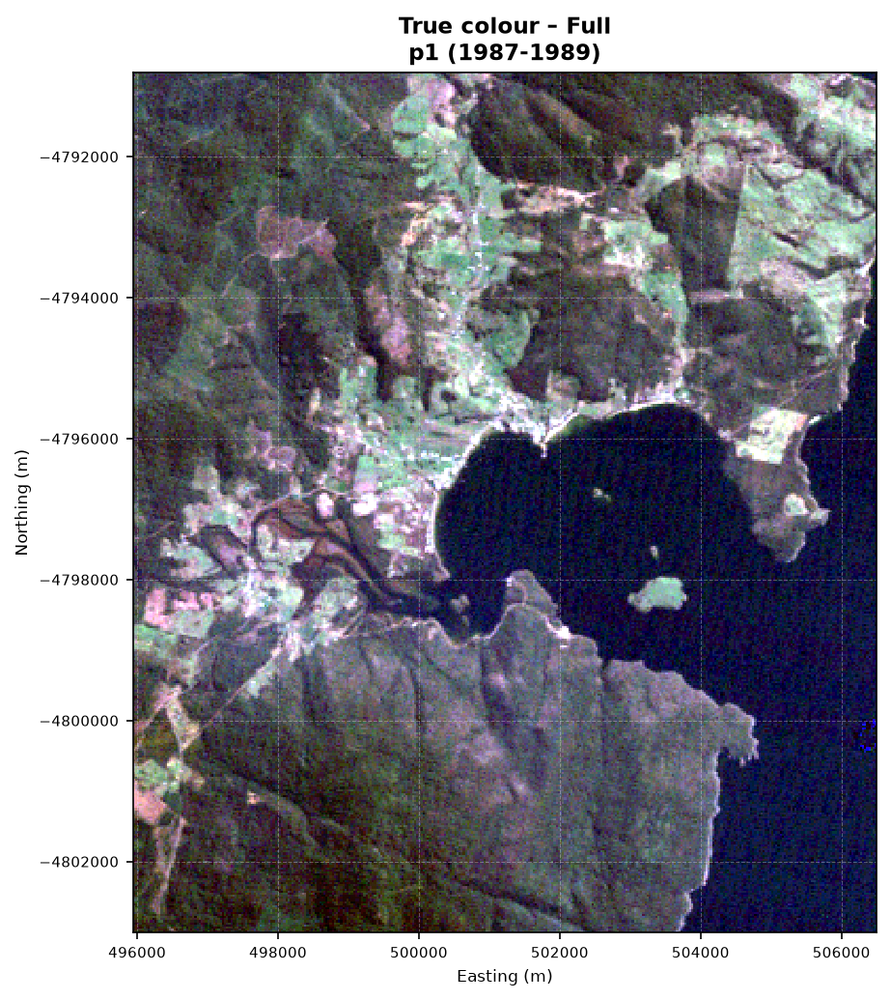

  [ok] p1_1987-1989__true.tif -> true_colour_full_p1_1987-1989.png


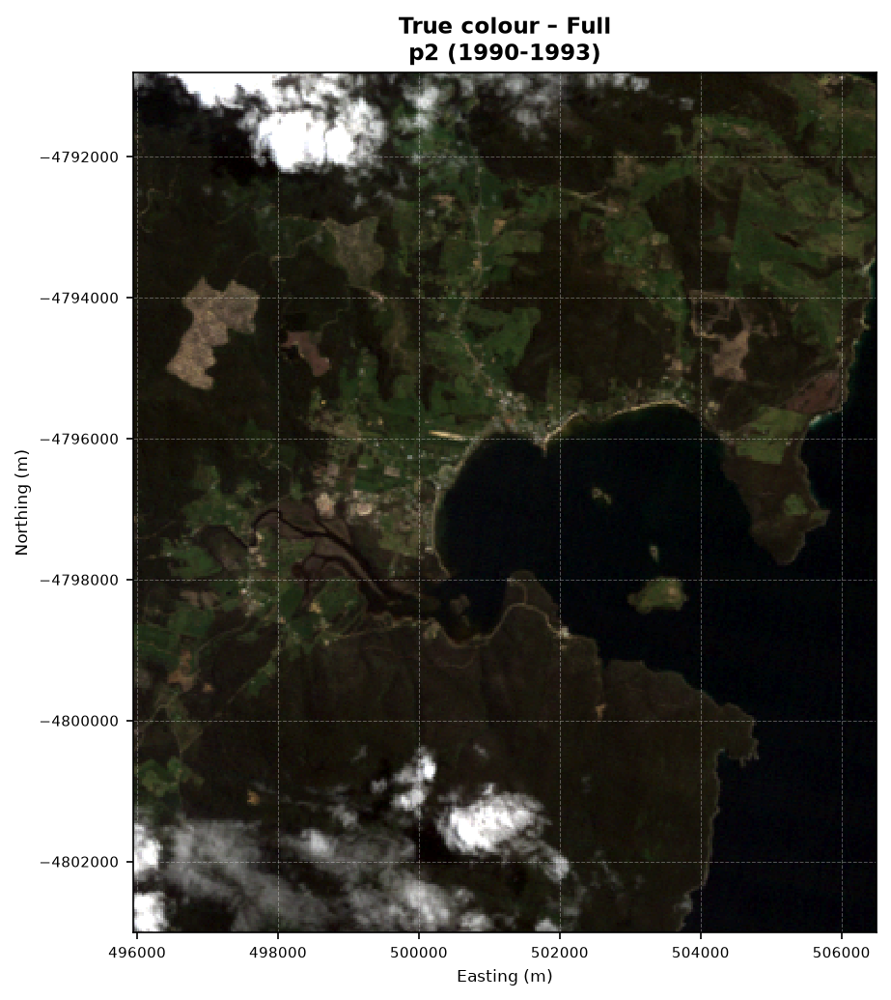

  [ok] p2_1990-1993_true.tif -> true_colour_full_p2_1990-1993.png


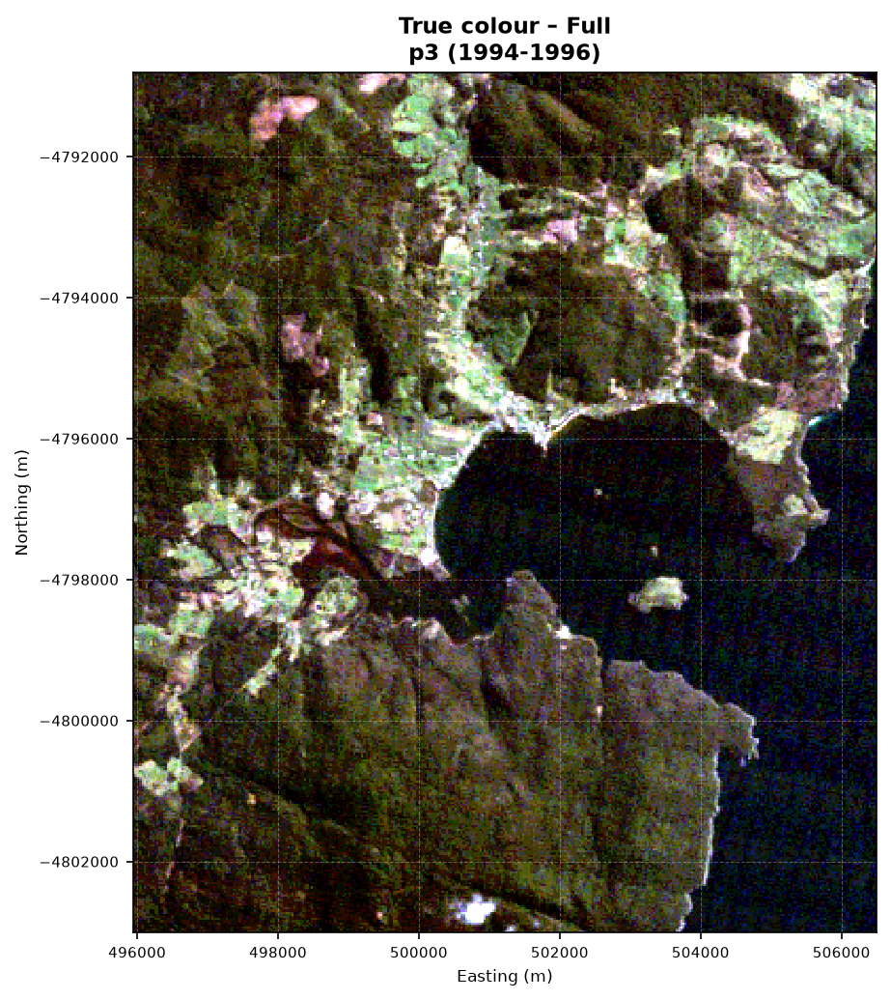

  [ok] p3_1994-1996_true.tif -> true_colour_full_p3_1994-1996.png


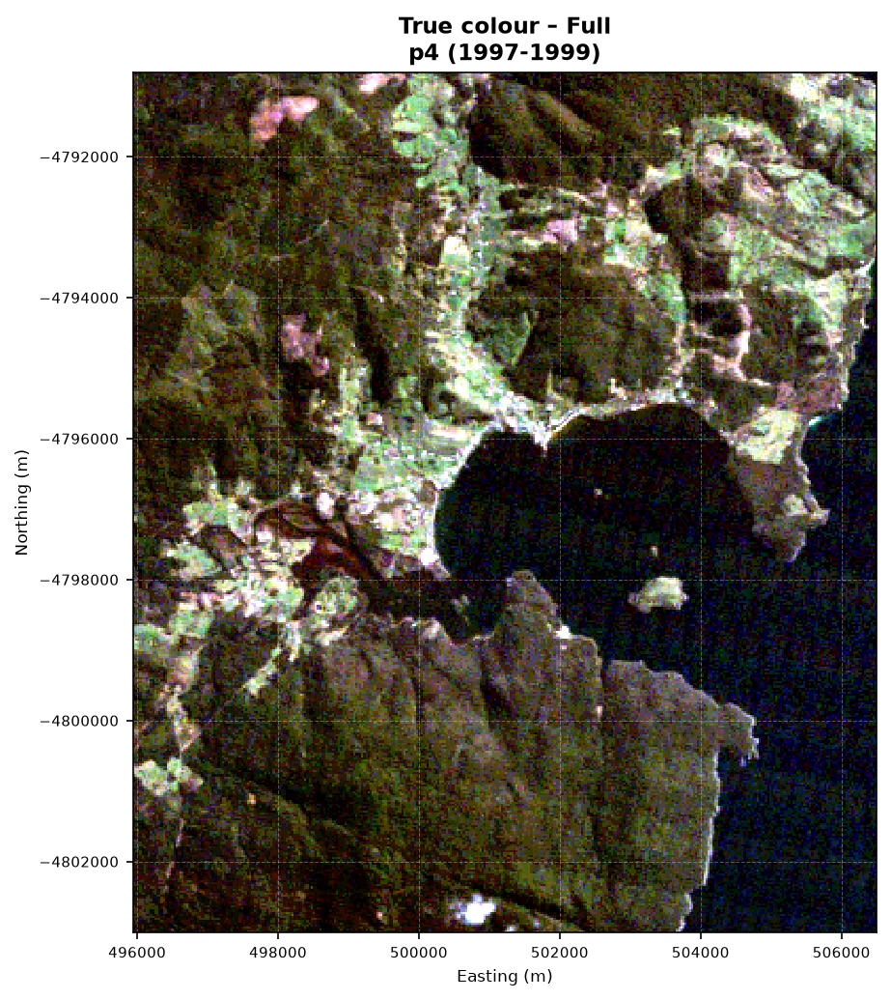

  [ok] p4_1997-1999_true.tif -> true_colour_full_p4_1997-1999.png


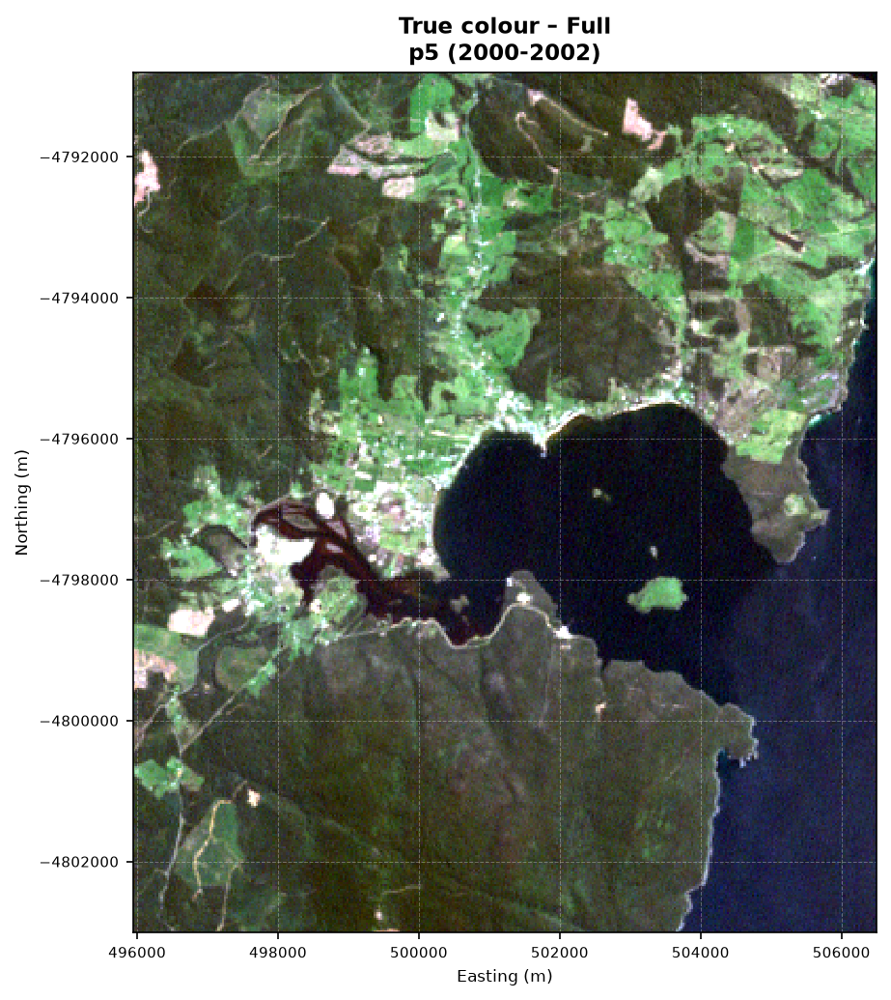

  [ok] p5_2000-2002_true.tif -> true_colour_full_p5_2000-2002.png


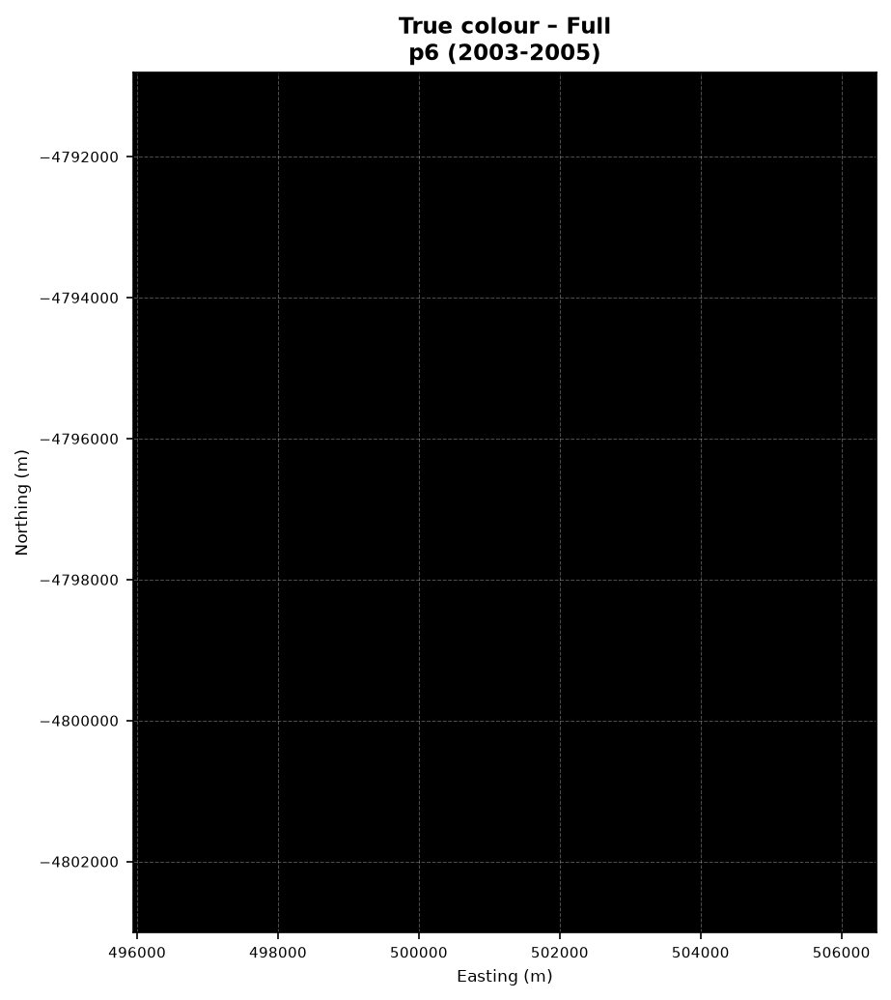

  [ok] p6_2003-2005_true.tif -> true_colour_full_p6_2003-2005.png


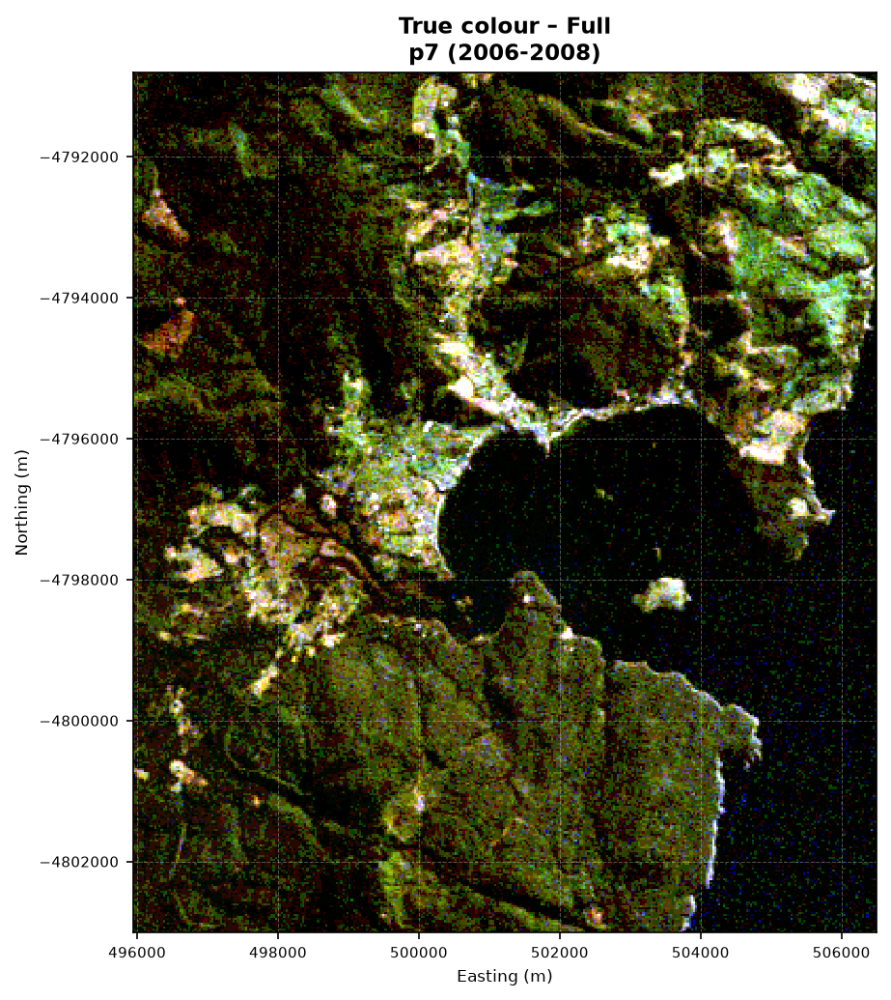

  [ok] p7_2006-2008_true.tif -> true_colour_full_p7_2006-2008.png


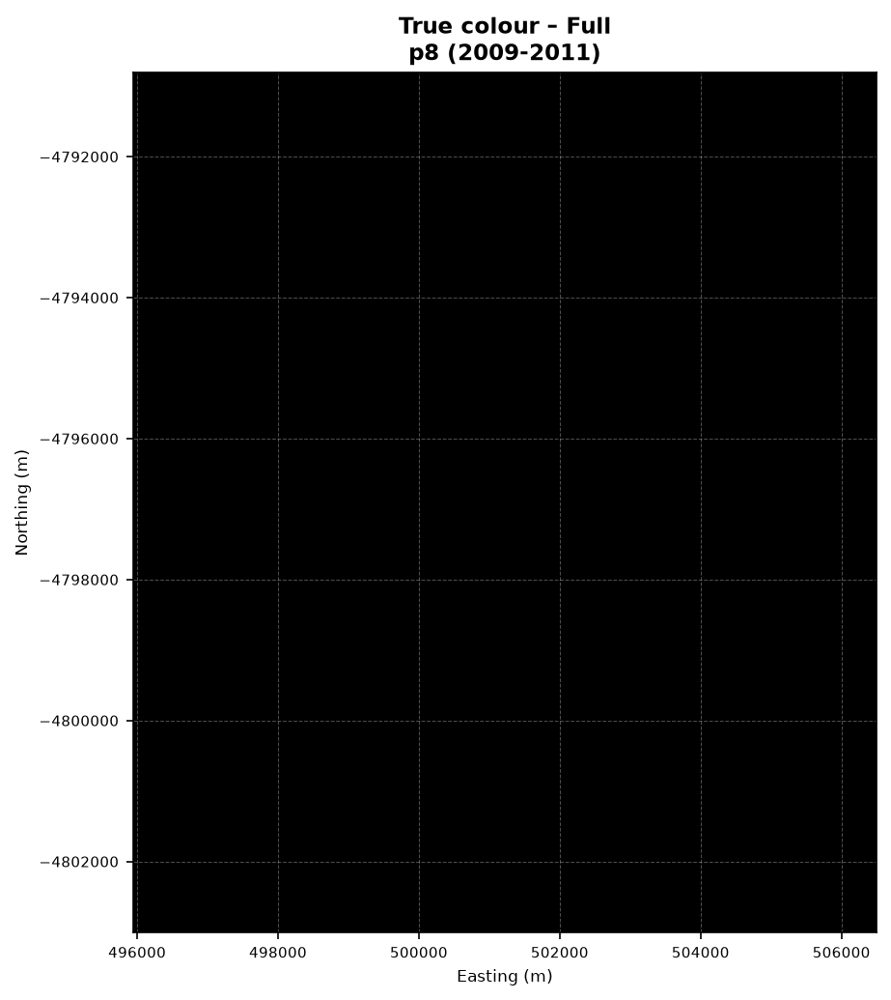

  [ok] p8_2009-2011_true.tif -> true_colour_full_p8_2009-2011.png


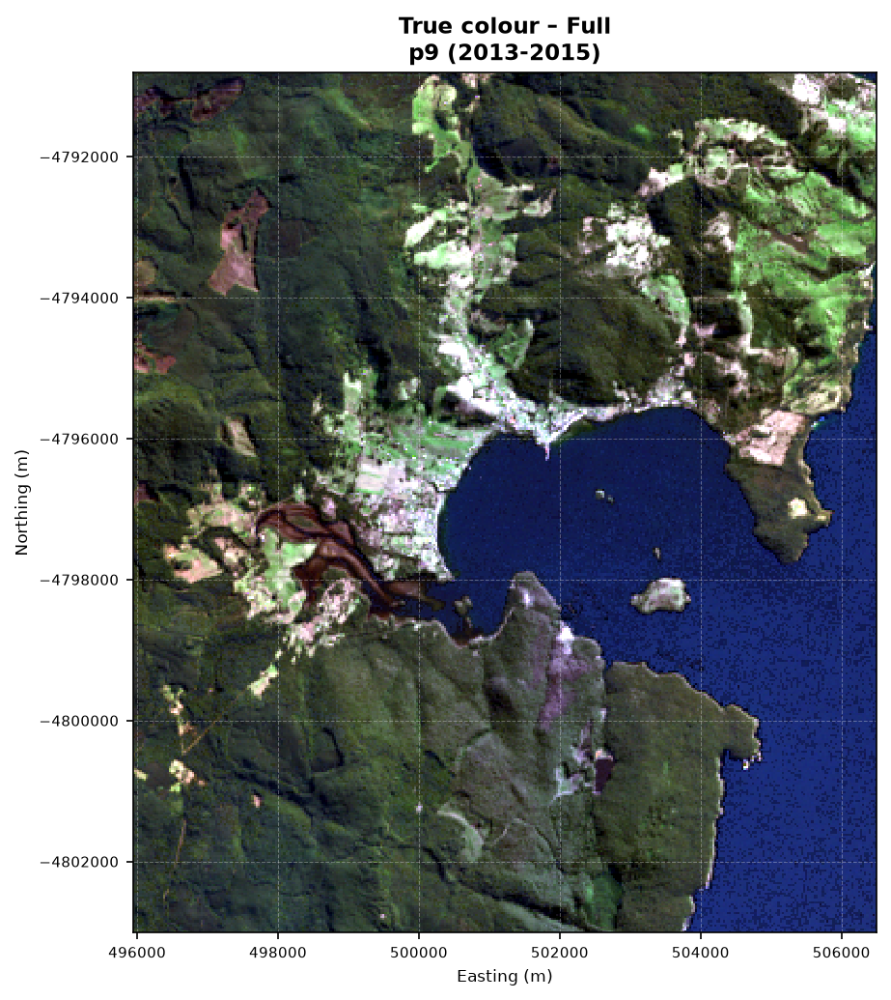

  [ok] p9_2013-2015_true.tif -> true_colour_full_p9_2013-2015.png

=== True colour – Masked (9 files) ===


/var/folders/13/hqwkrjhs62ndsg0fg_ln80hr0000gn/T/ipykernel_55856/3289788461.py:13: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  crop = src.read(window=window, boundless=True, masked=True)


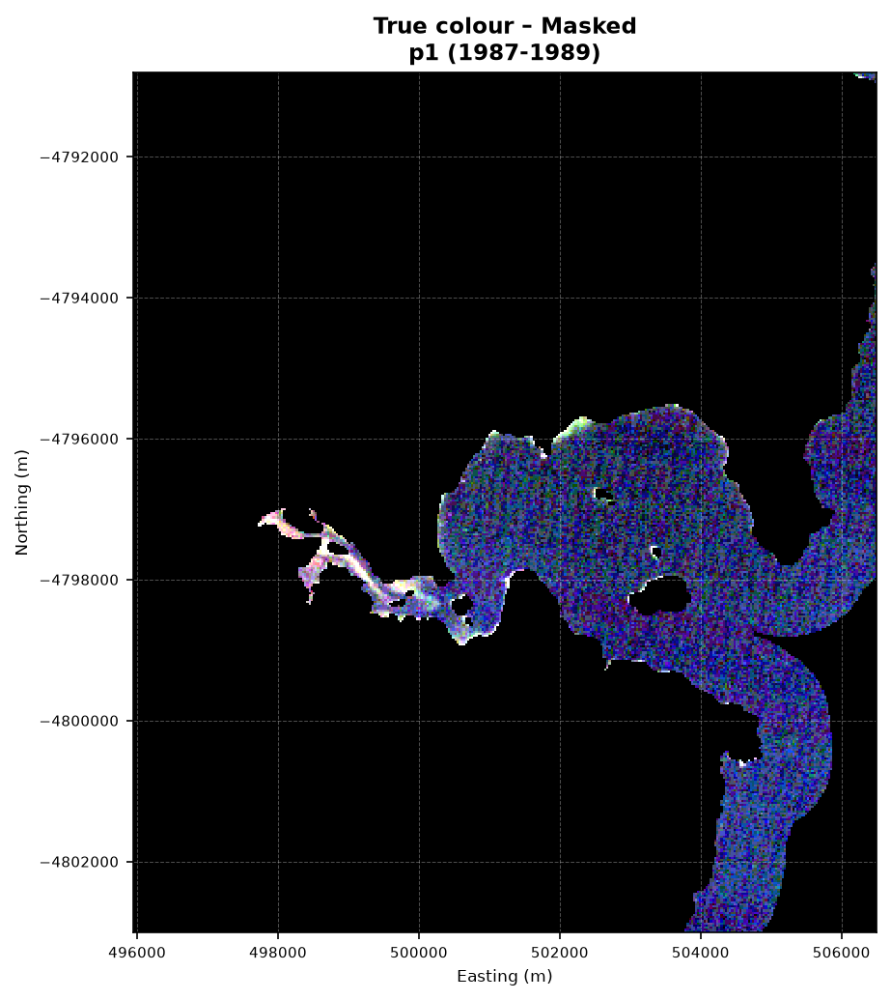

  [ok] p1_1987-1989_true_masked.tif -> true_colour_masked_p1_1987-1989.png


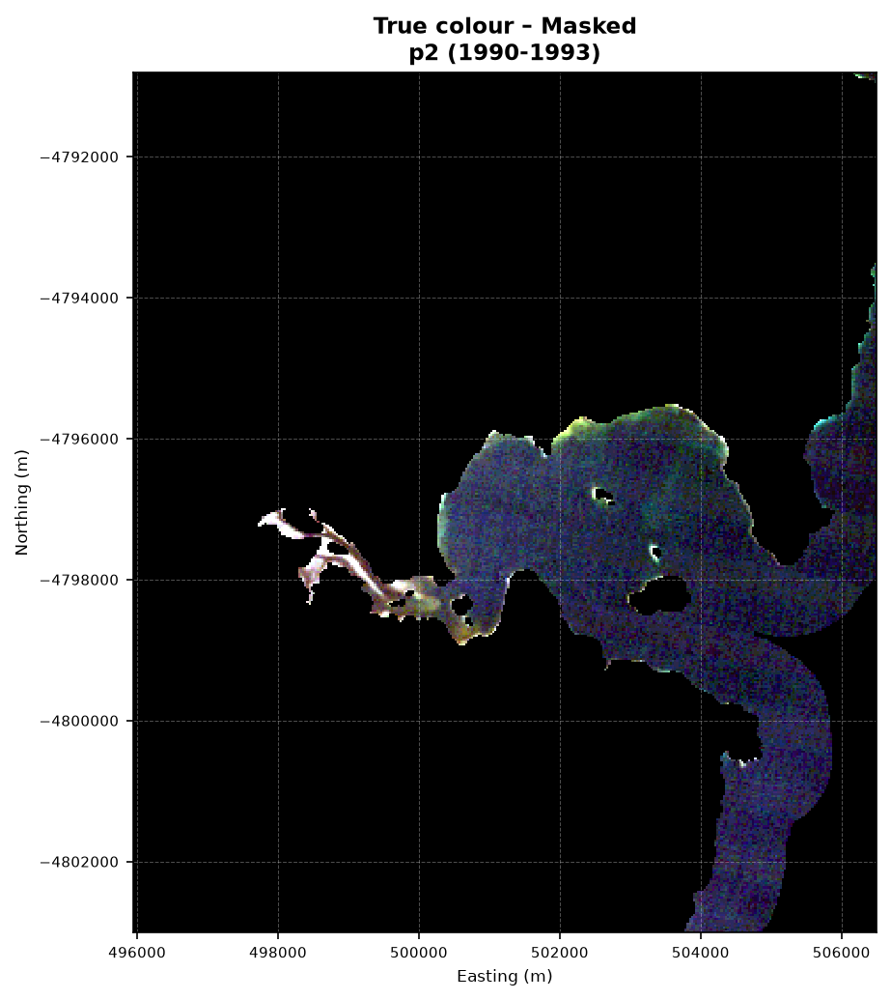

  [ok] p2_1990-1993_true_masked.tif -> true_colour_masked_p2_1990-1993.png


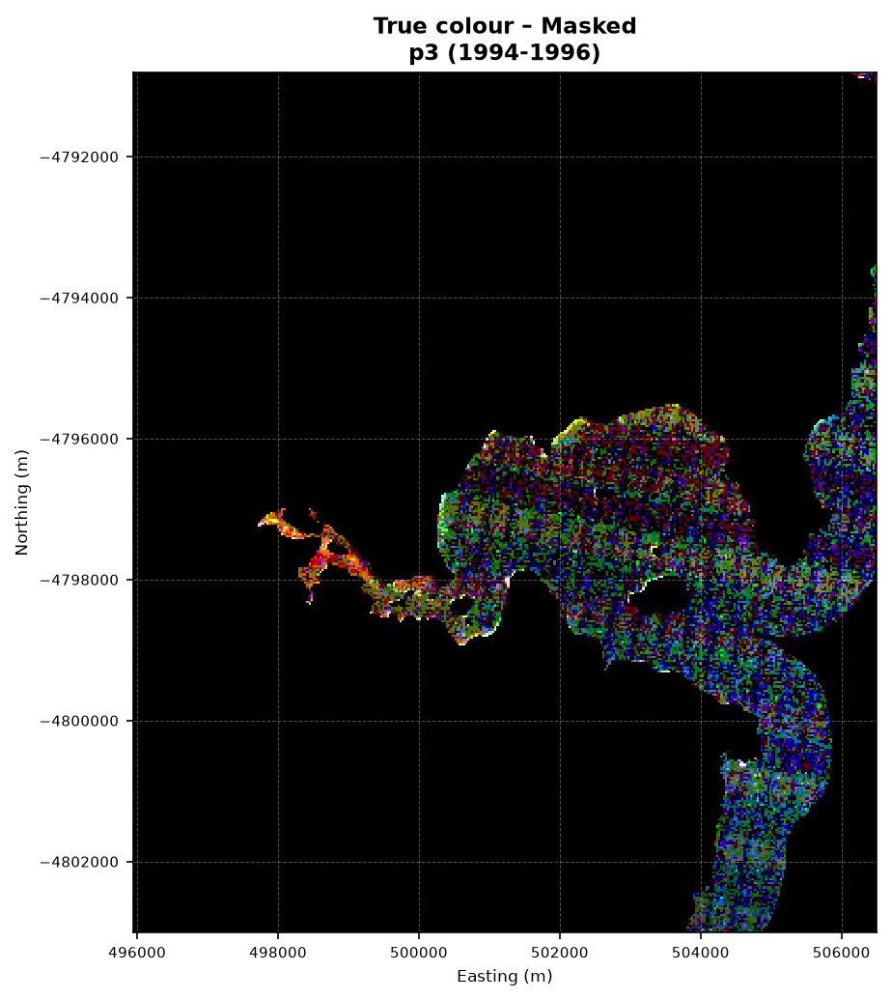

  [ok] p3_1994-1996_true_masked.tif -> true_colour_masked_p3_1994-1996.png


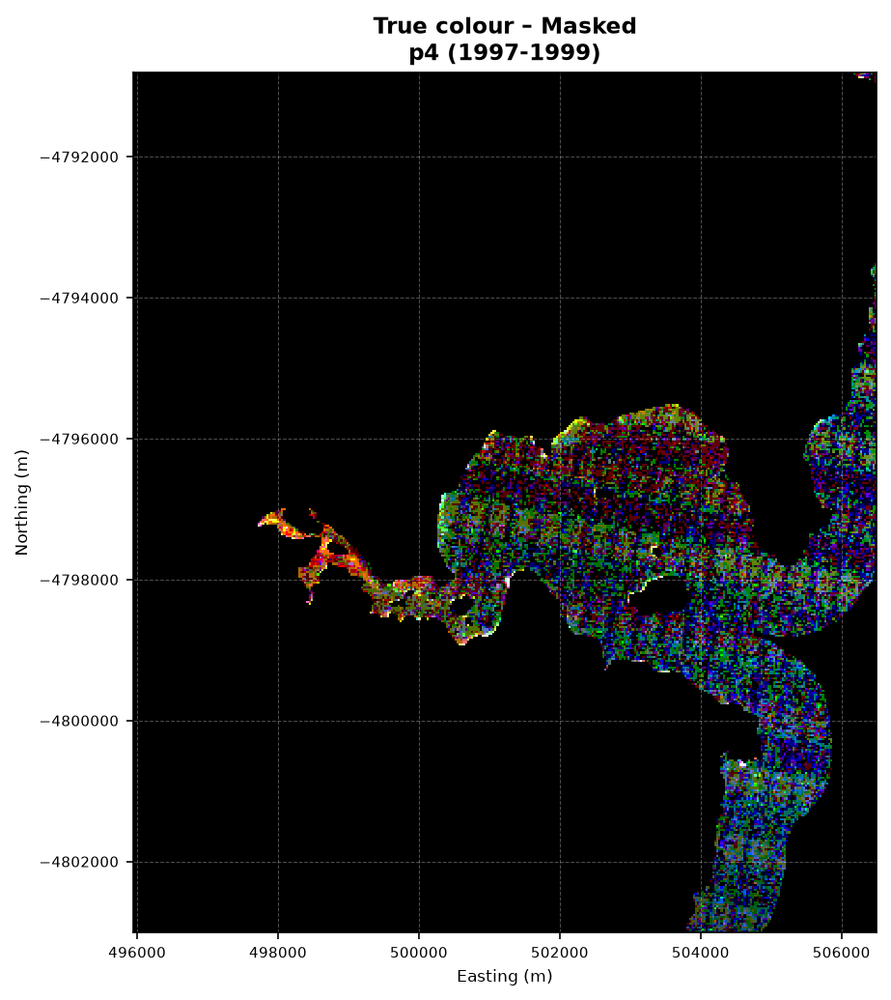

  [ok] p4_1997-1999_true_masked.tif -> true_colour_masked_p4_1997-1999.png


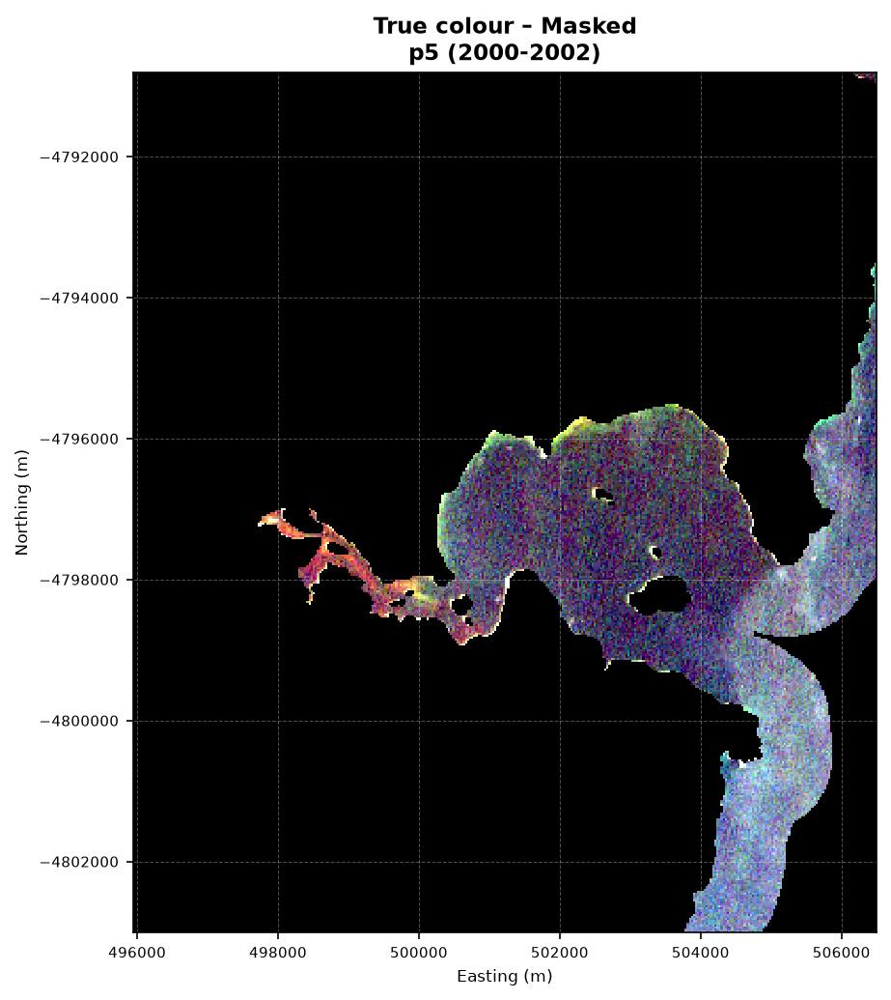

  [ok] p5_2000-2002_true_masked.tif -> true_colour_masked_p5_2000-2002.png


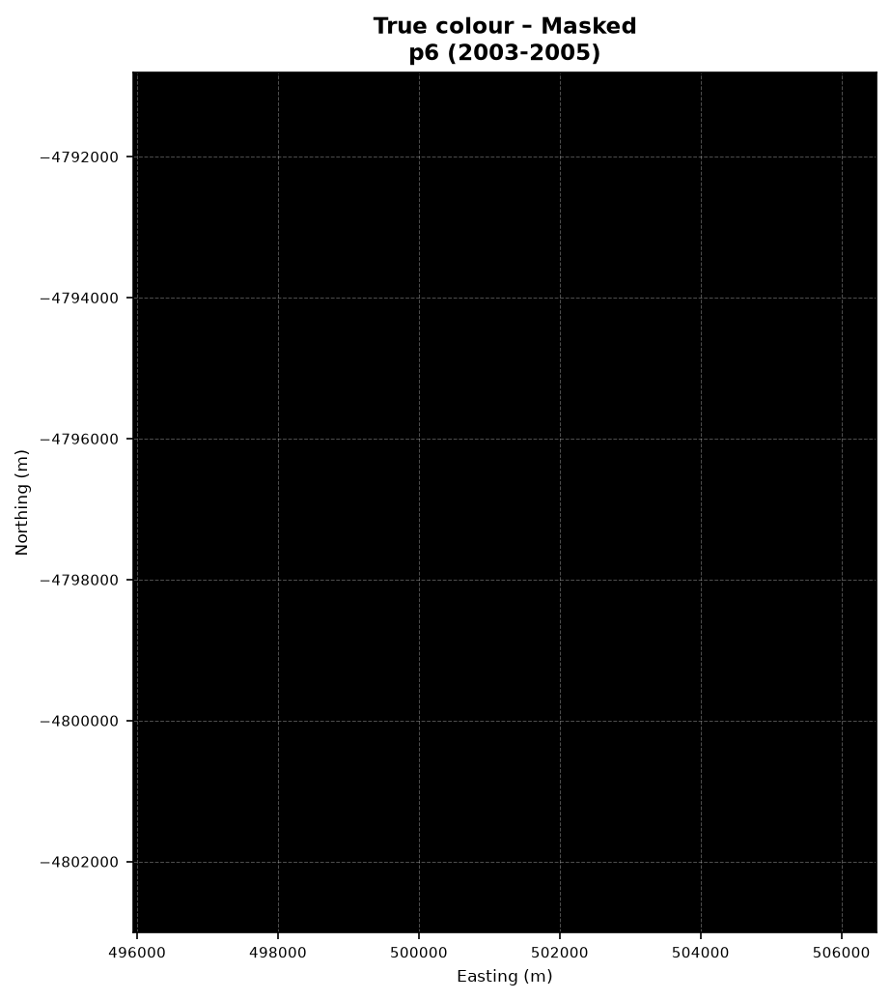

  [ok] p6_2003-2005_true_masked.tif -> true_colour_masked_p6_2003-2005.png


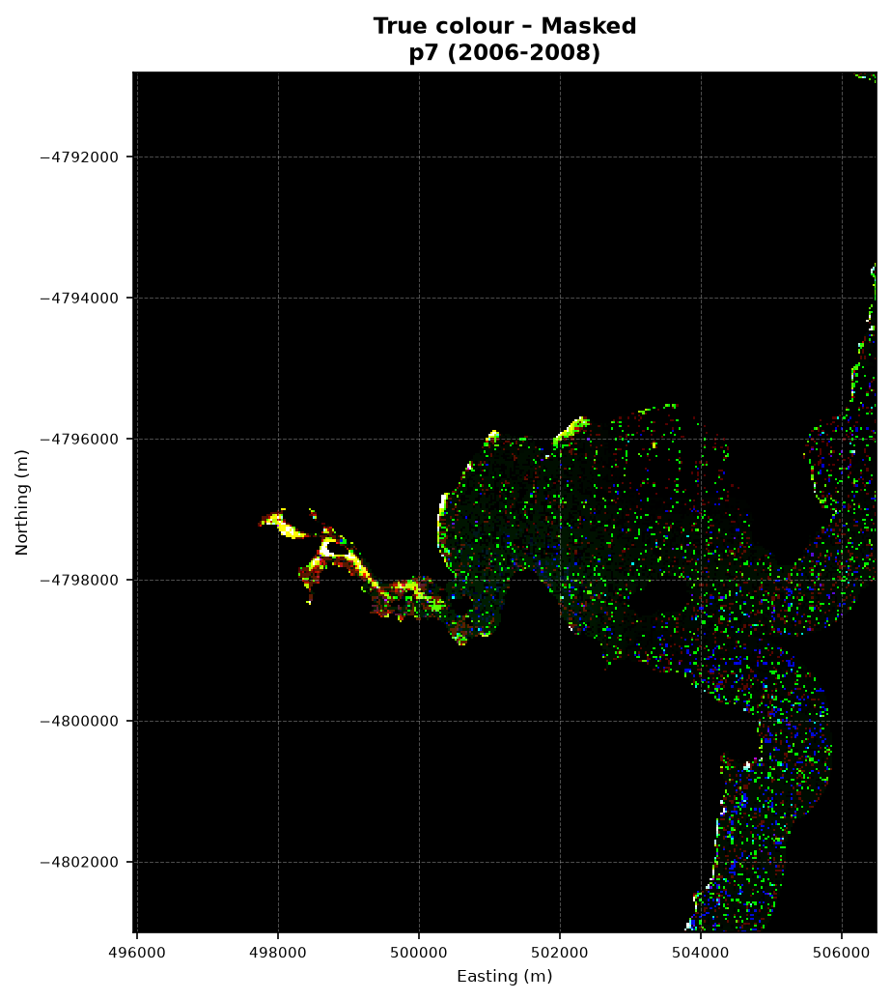

  [ok] p7_2006-2008_true_masked.tif -> true_colour_masked_p7_2006-2008.png


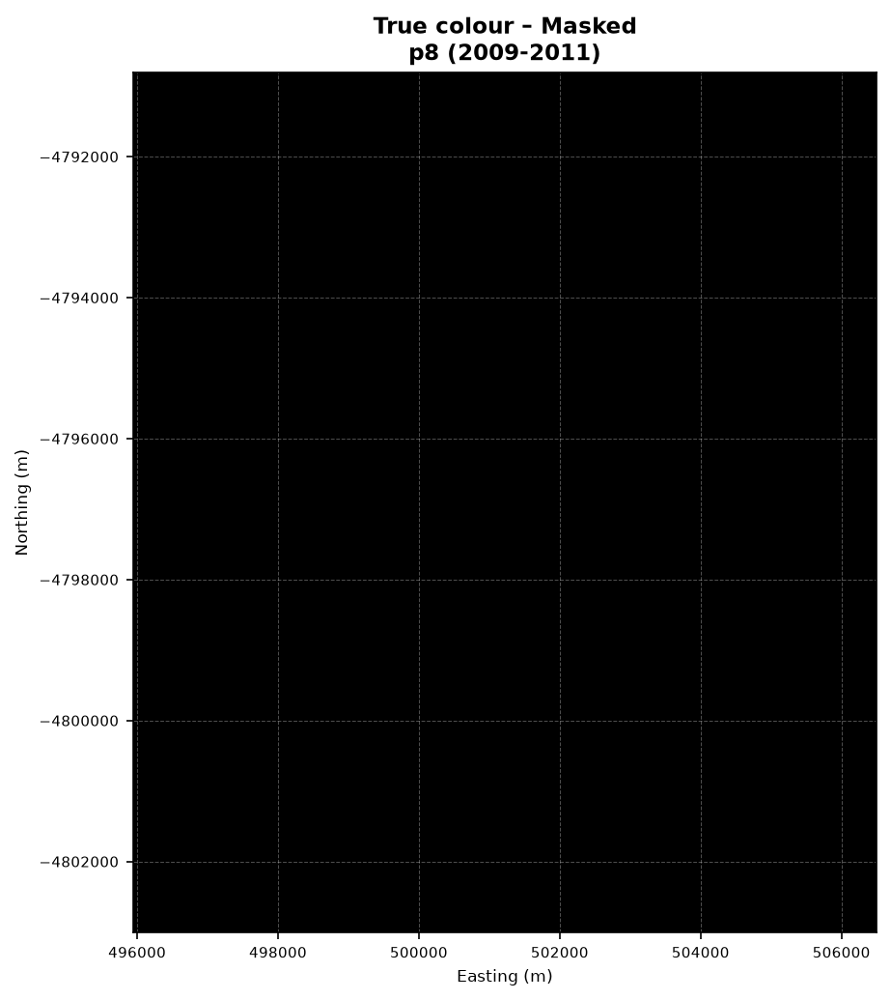

  [ok] p8_2009-2011_true_masked.tif -> true_colour_masked_p8_2009-2011.png


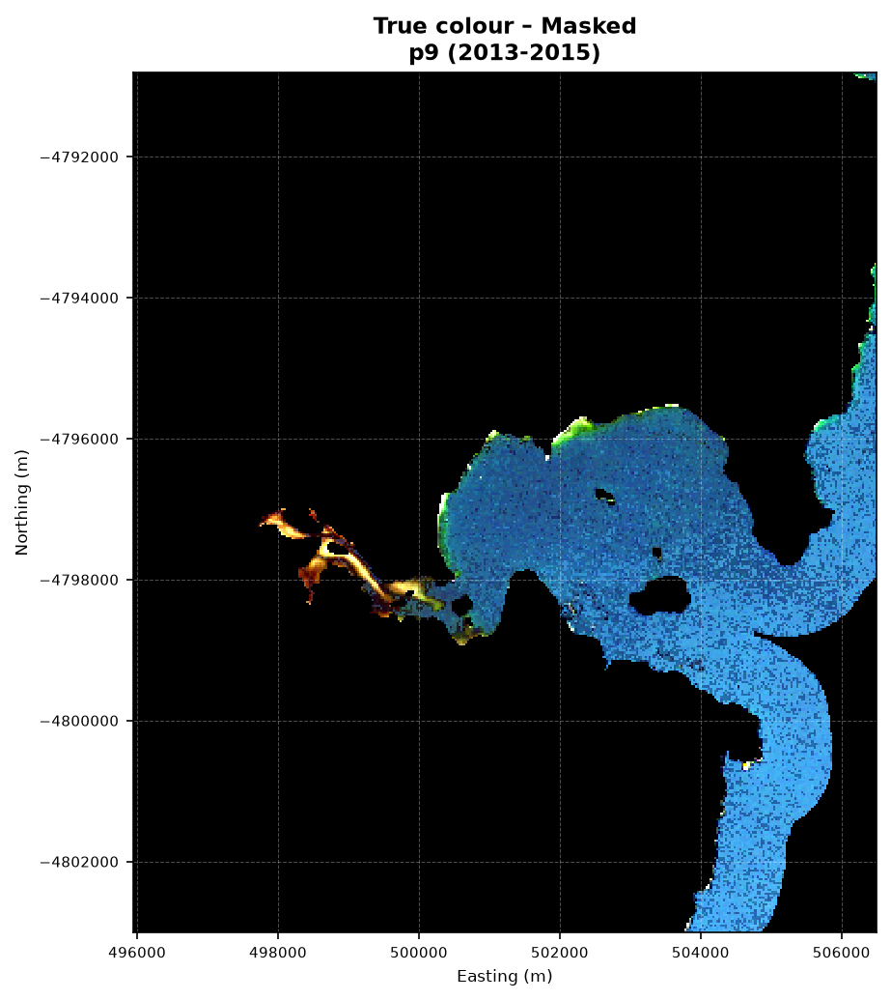

  [ok] p9_2013-2015_true_masked.tif -> true_colour_masked_p9_2013-2015.png

=== False colour – Full (9 files) ===


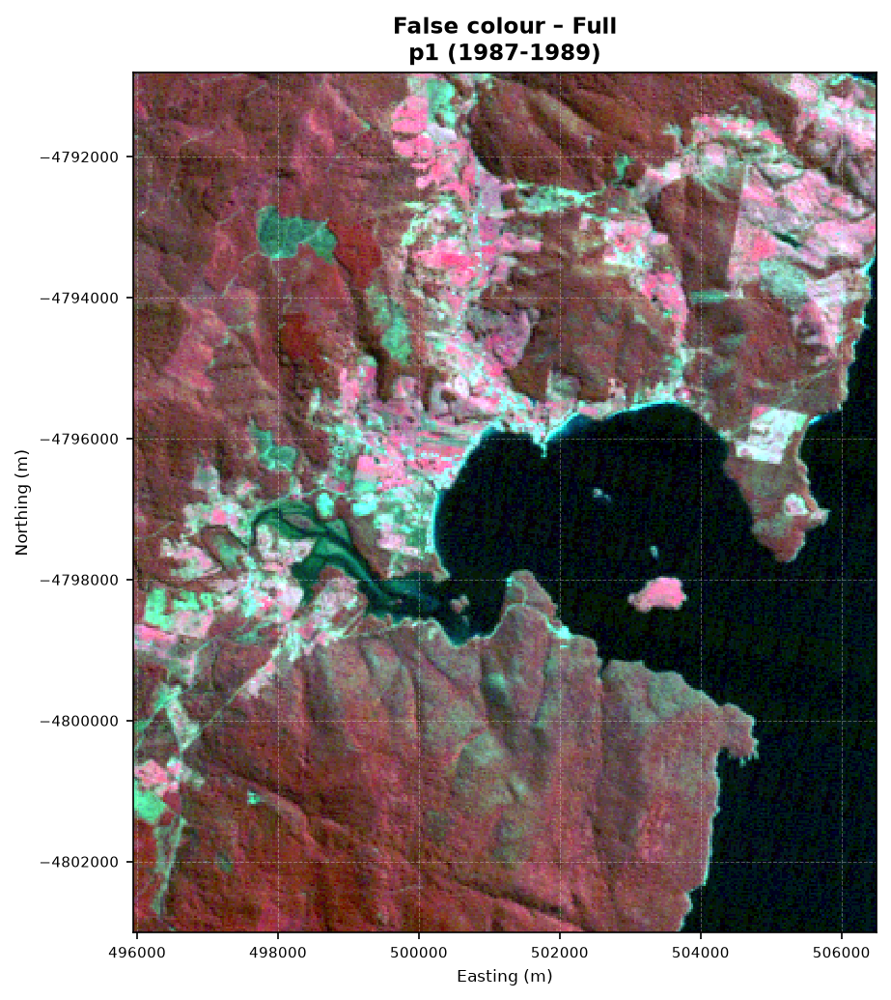

  [ok] p1_1987-1989_false.tif -> false_colour_full_p1_1987-1989.png


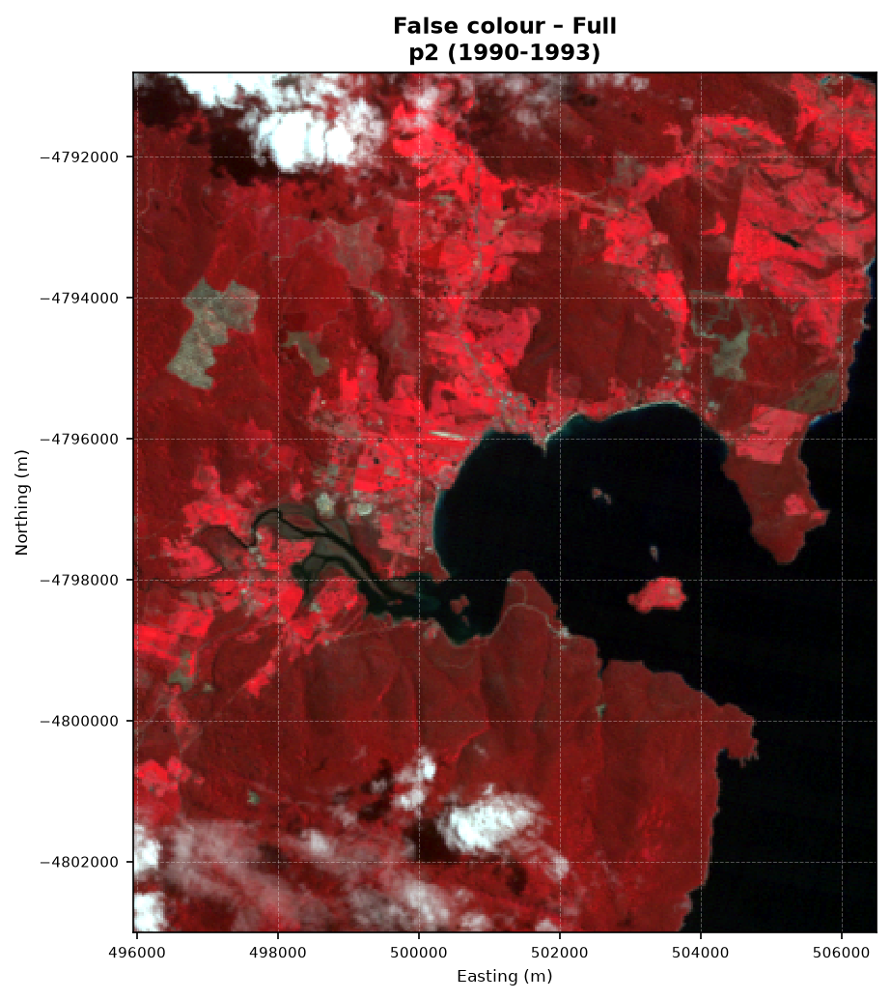

  [ok] p2_1990-1993_false.tif -> false_colour_full_p2_1990-1993.png


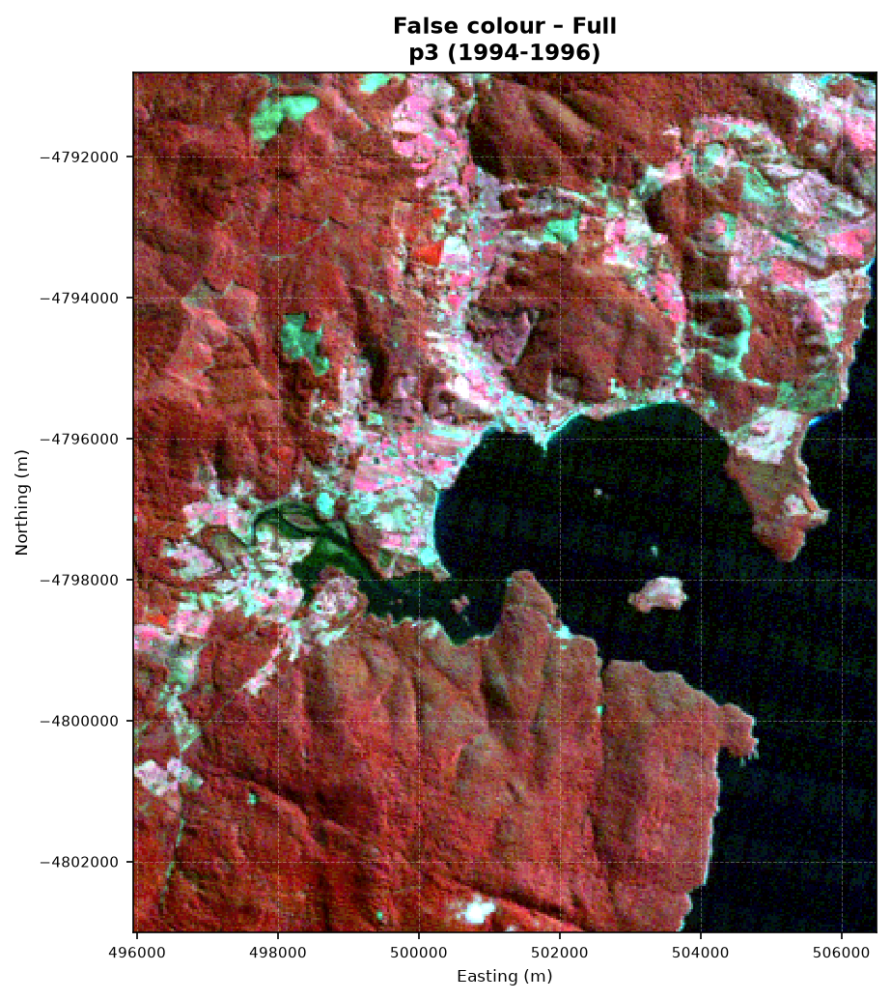

  [ok] p3_1994-1996_false.tif -> false_colour_full_p3_1994-1996.png


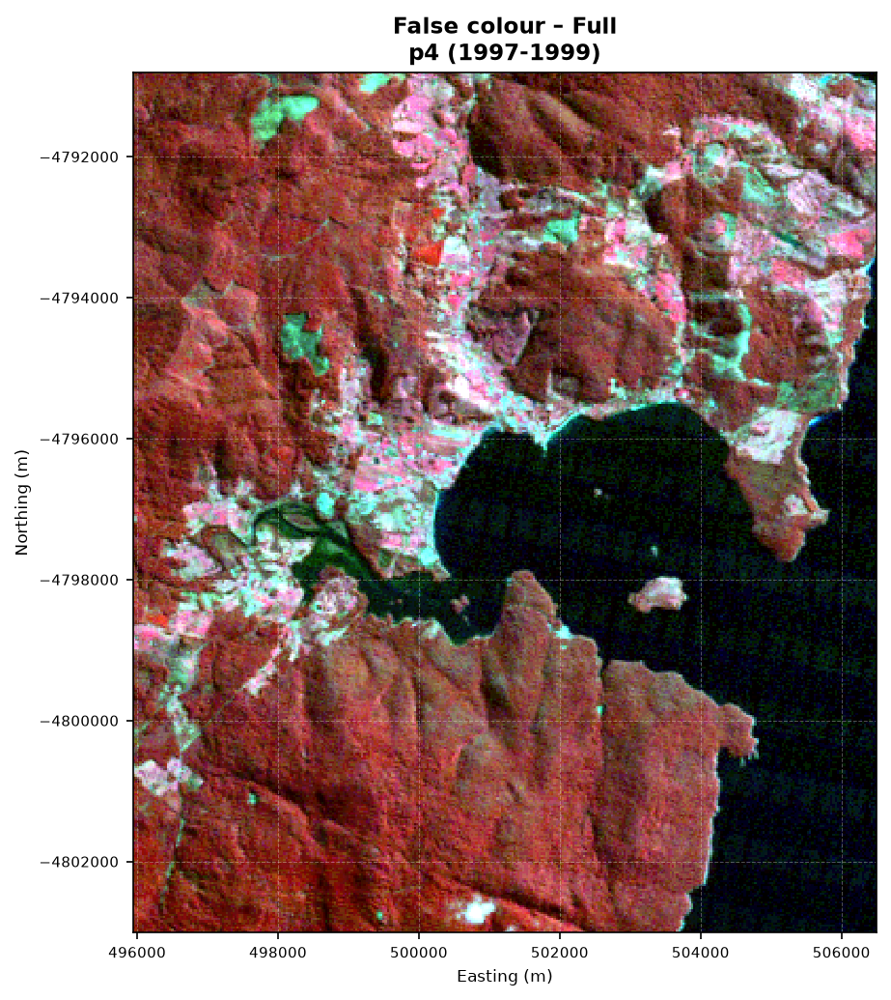

  [ok] p4_1997-1999_false.tif -> false_colour_full_p4_1997-1999.png


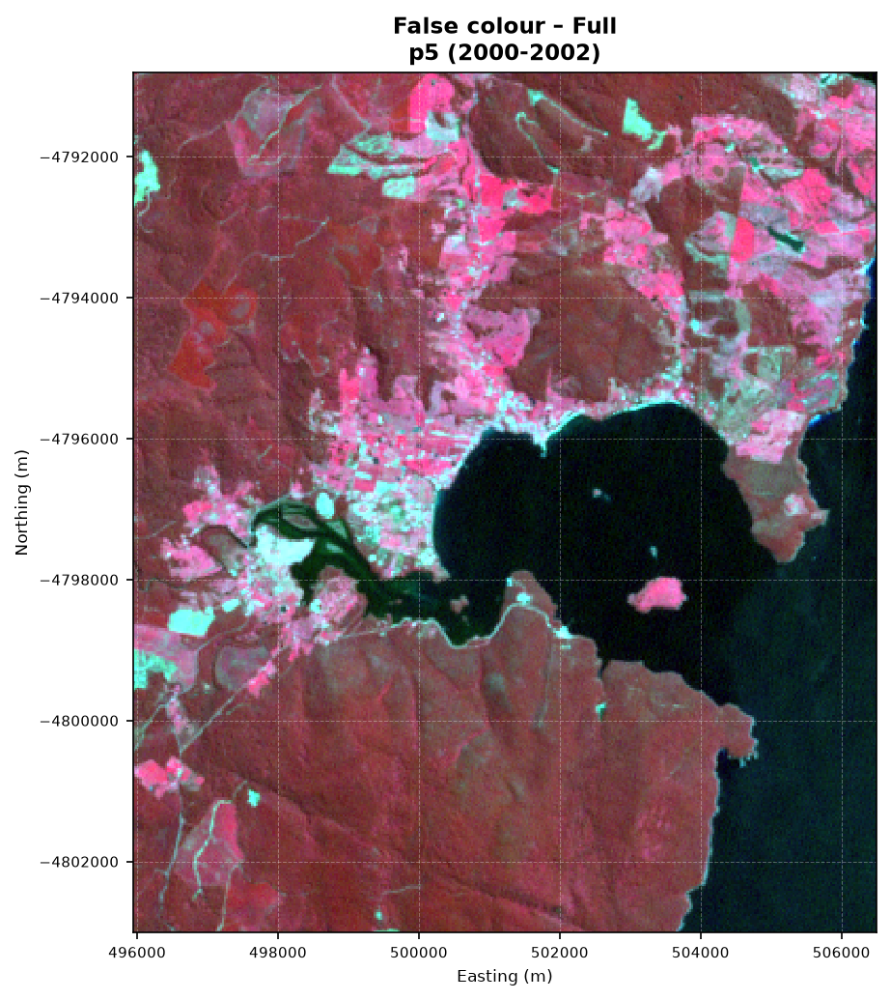

  [ok] p5_2000-2002_false.tif -> false_colour_full_p5_2000-2002.png


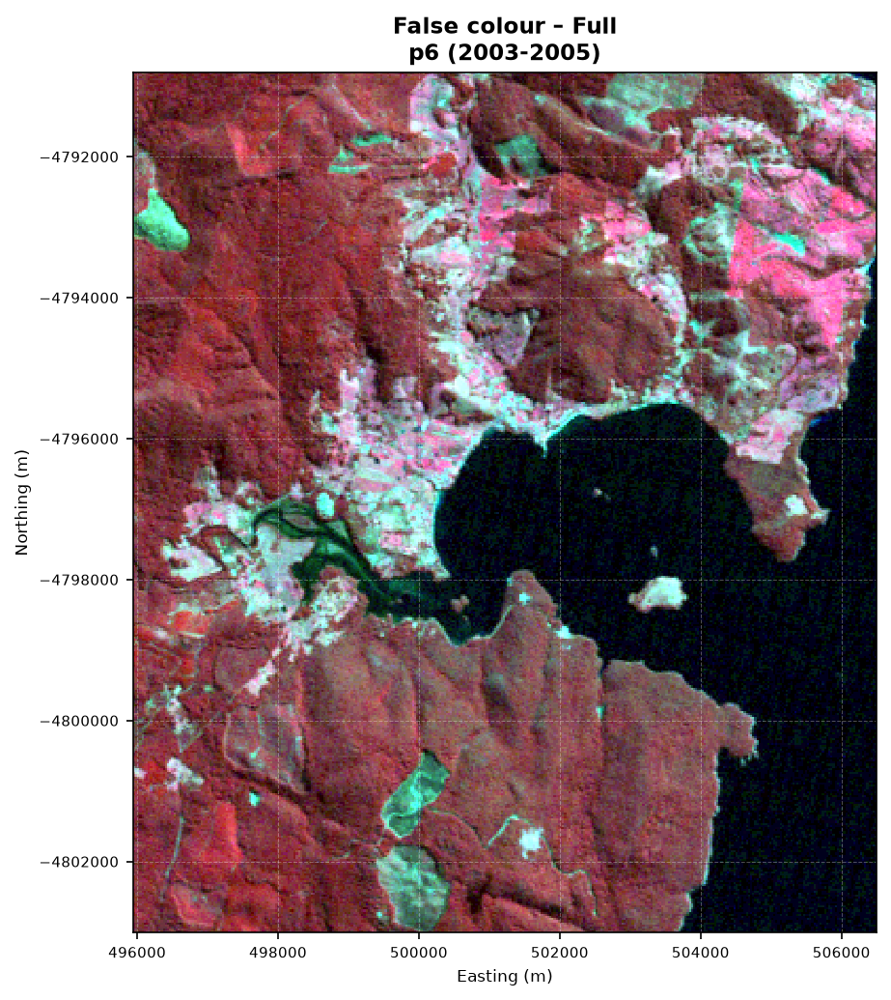

  [ok] p6_2003-2005_false.tif -> false_colour_full_p6_2003-2005.png


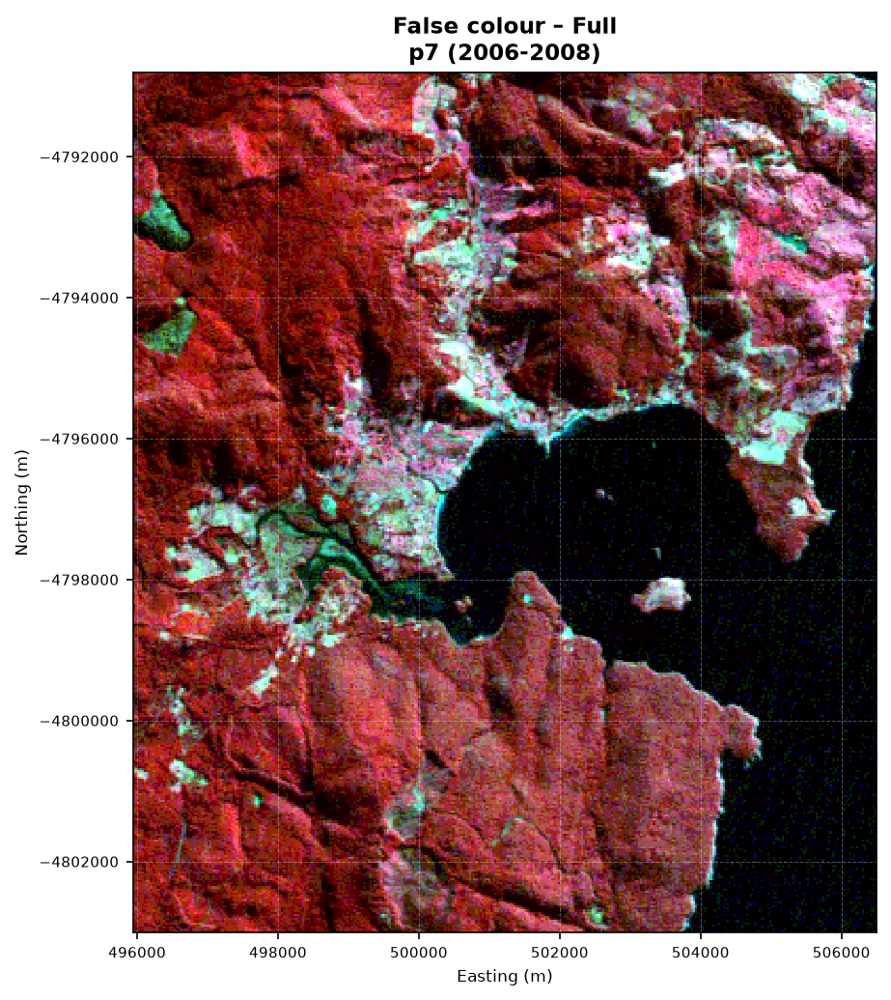

  [ok] p7_2006-2008_false.tif -> false_colour_full_p7_2006-2008.png


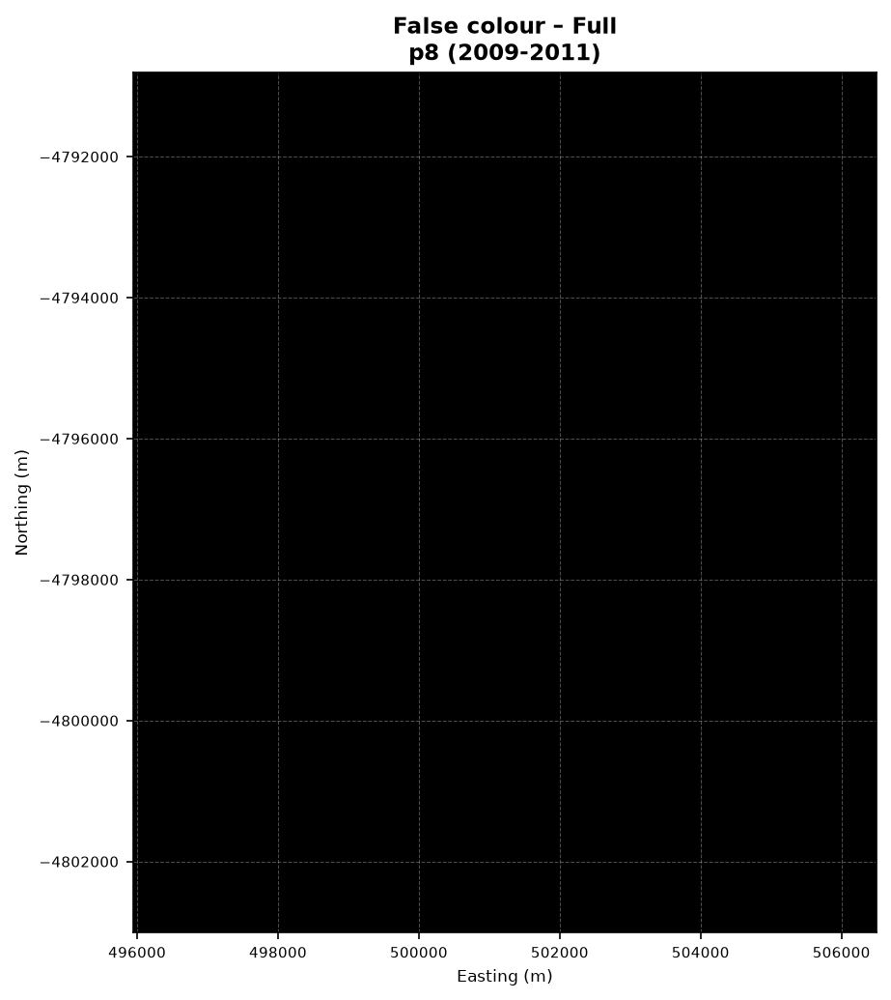

  [ok] p8_2009-2011_false.tif -> false_colour_full_p8_2009-2011.png


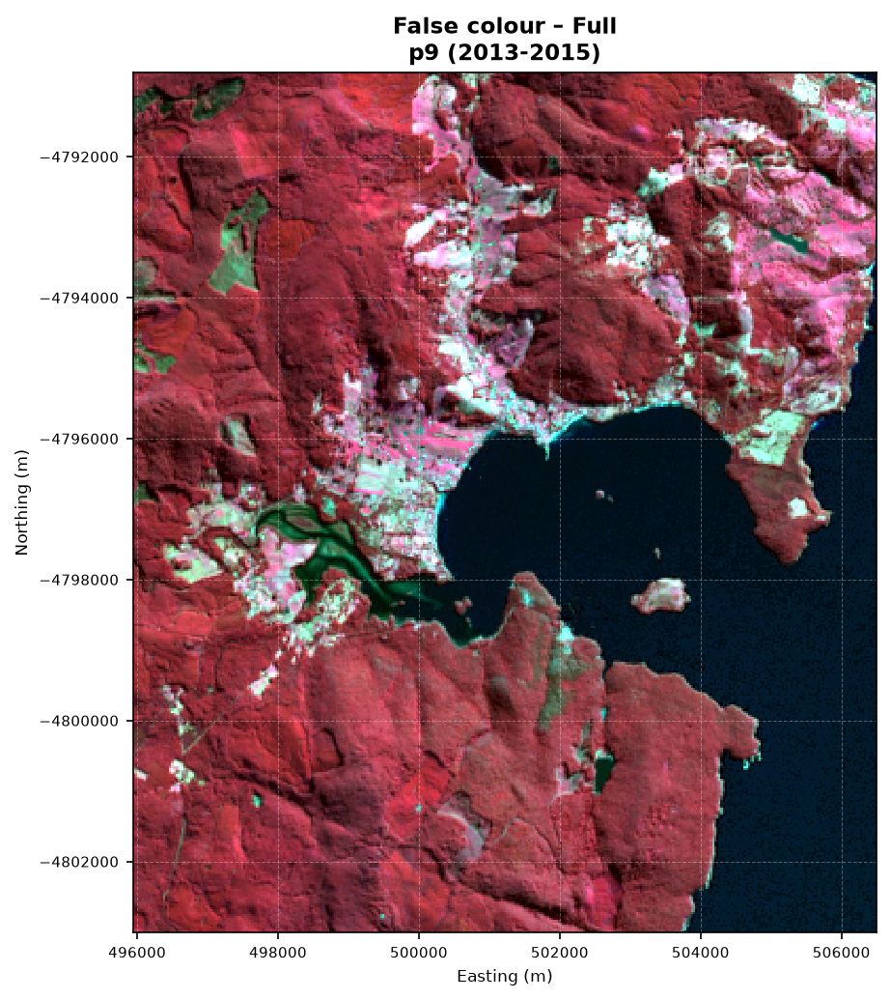

  [ok] p9_2013-2015_false.tif -> false_colour_full_p9_2013-2015.png

=== False colour – Masked (9 files) ===


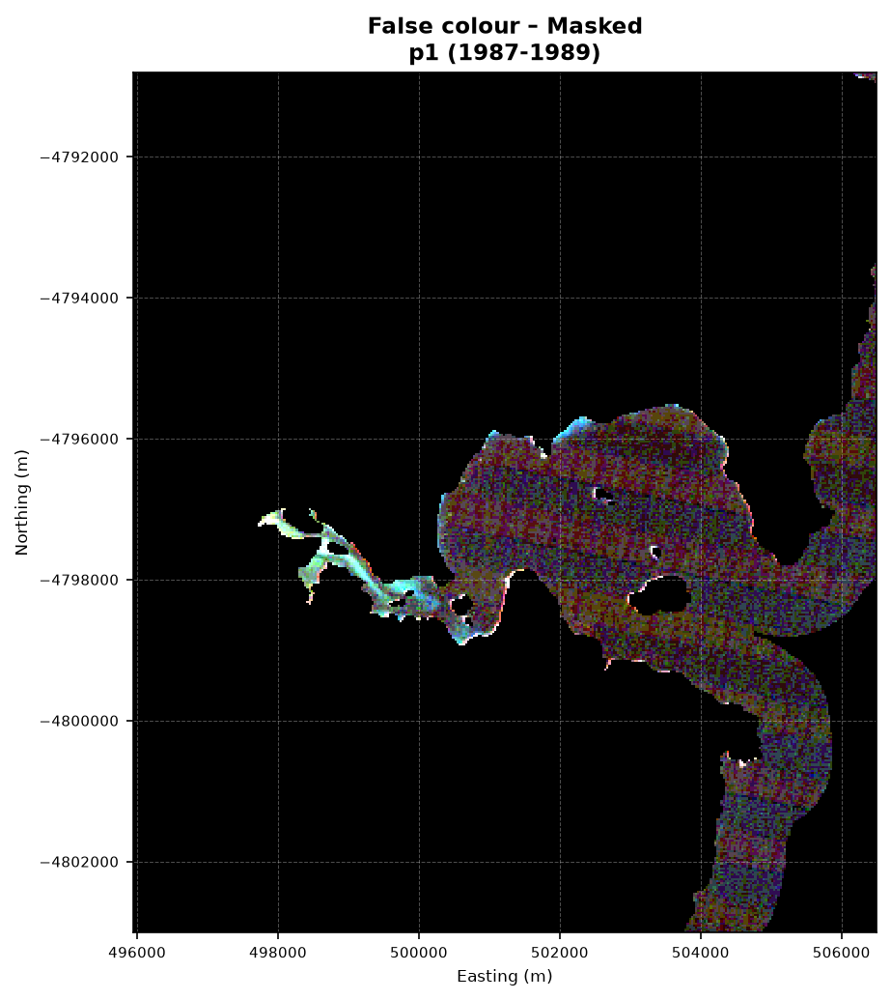

  [ok] p1_1987-1989_false_masked.tif -> false_colour_masked_p1_1987-1989.png


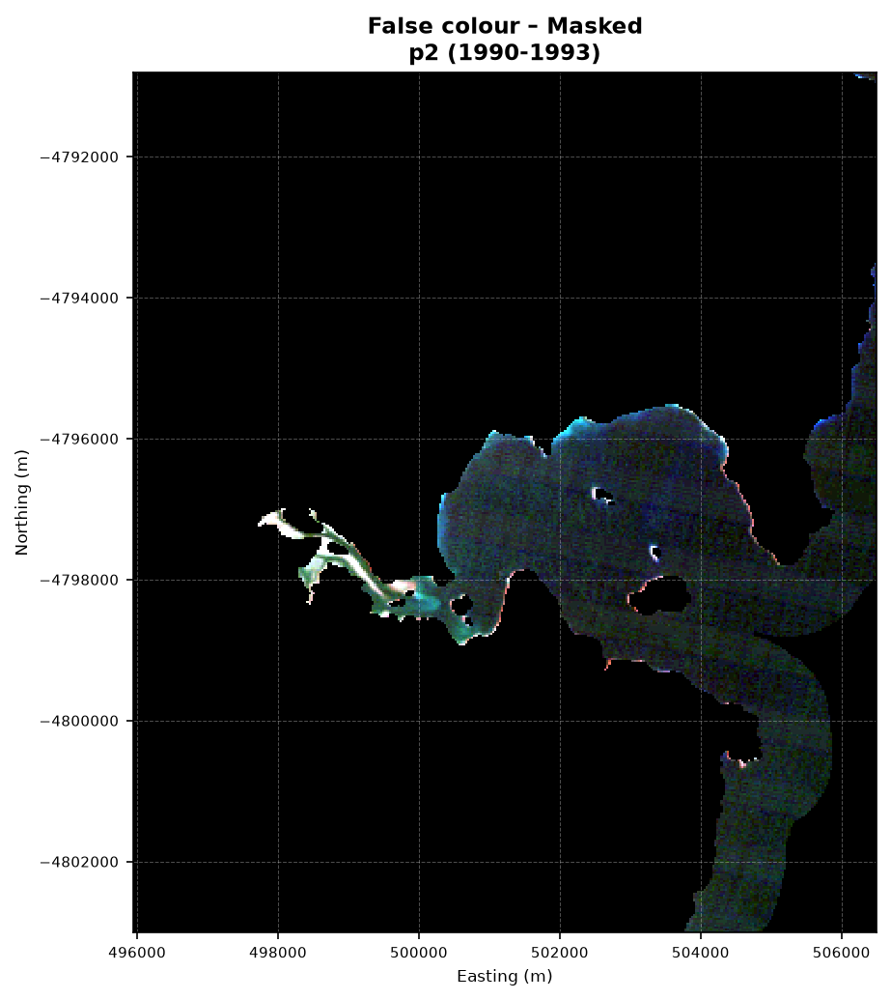

  [ok] p2_1990-1993_false_masked.tif -> false_colour_masked_p2_1990-1993.png


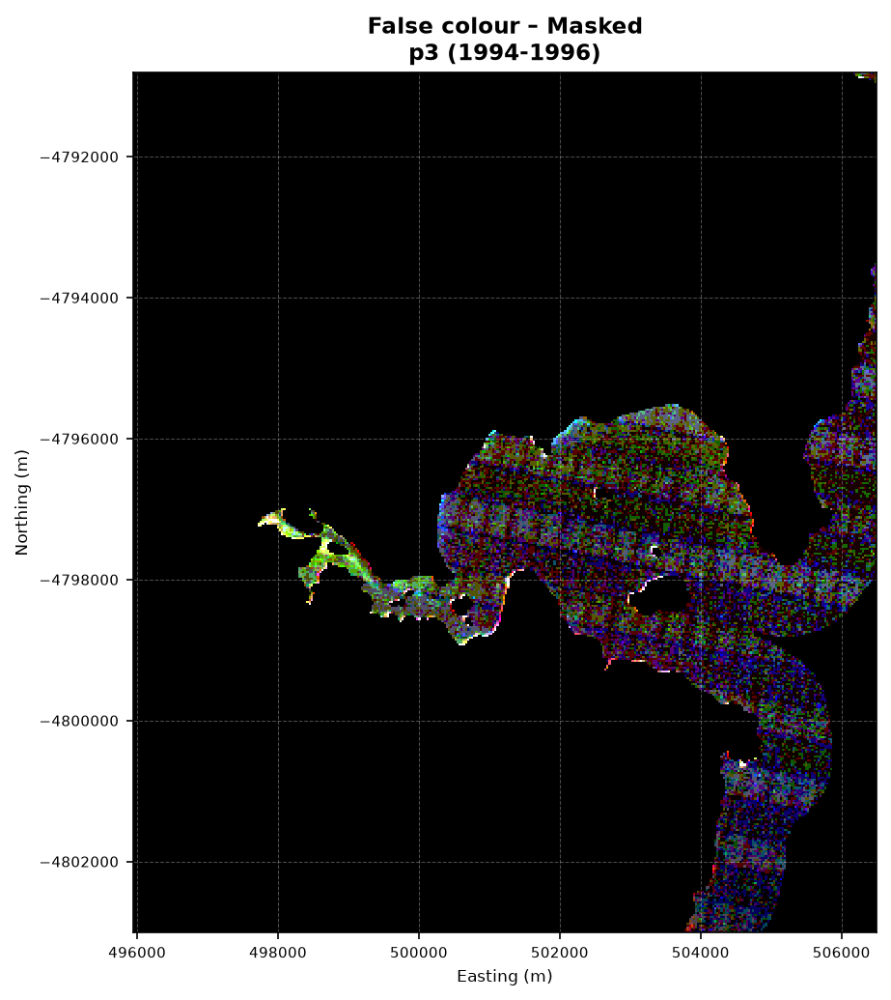

  [ok] p3_1994-1996_false_masked.tif -> false_colour_masked_p3_1994-1996.png


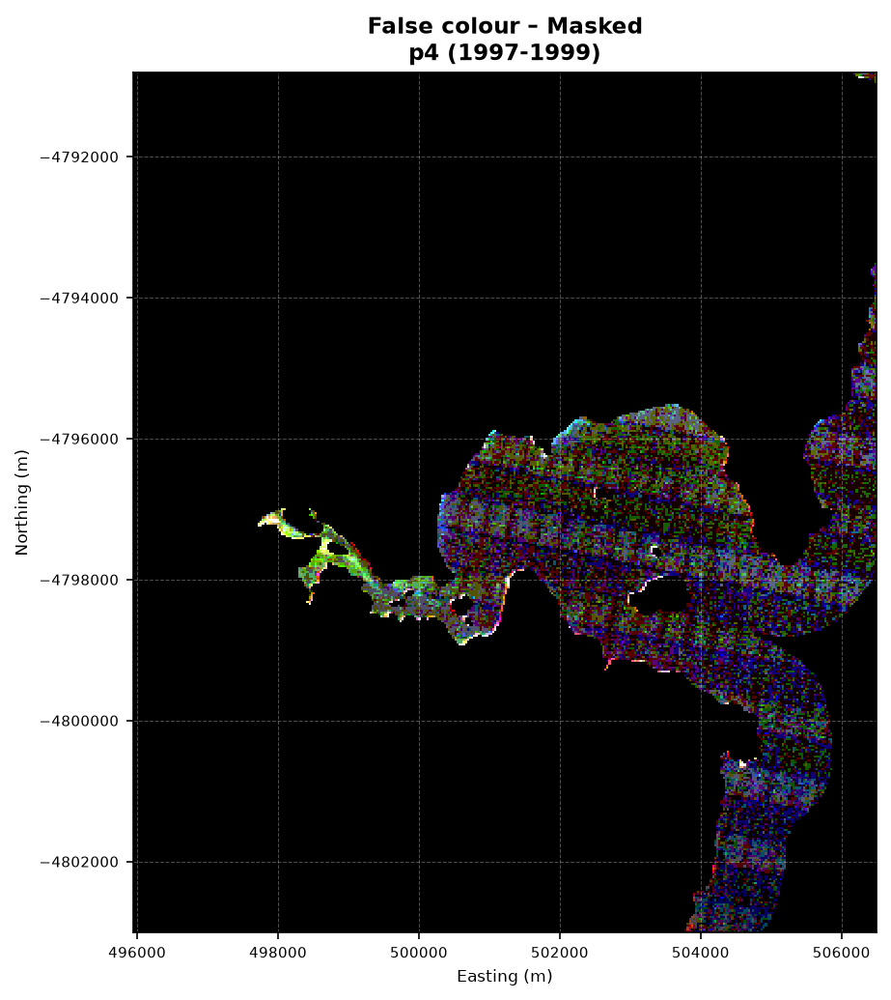

  [ok] p4_1997-1999_false_masked.tif -> false_colour_masked_p4_1997-1999.png


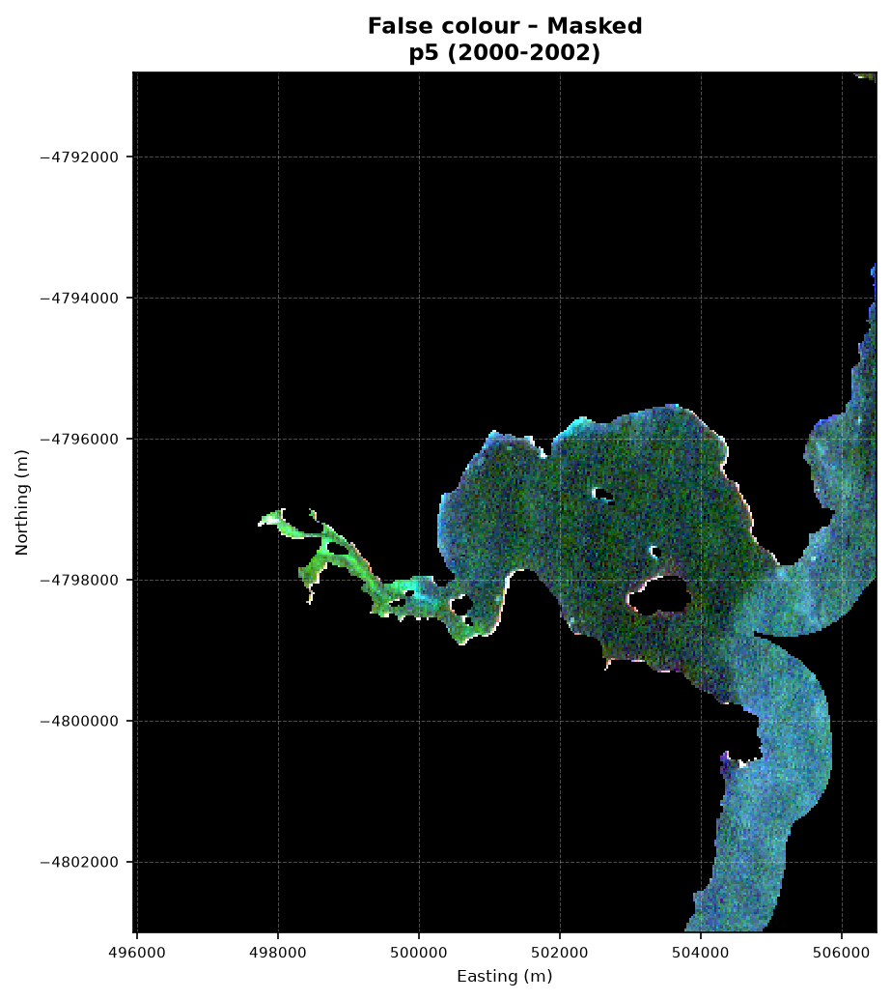

  [ok] p5_2000-2002_false_masked.tif -> false_colour_masked_p5_2000-2002.png


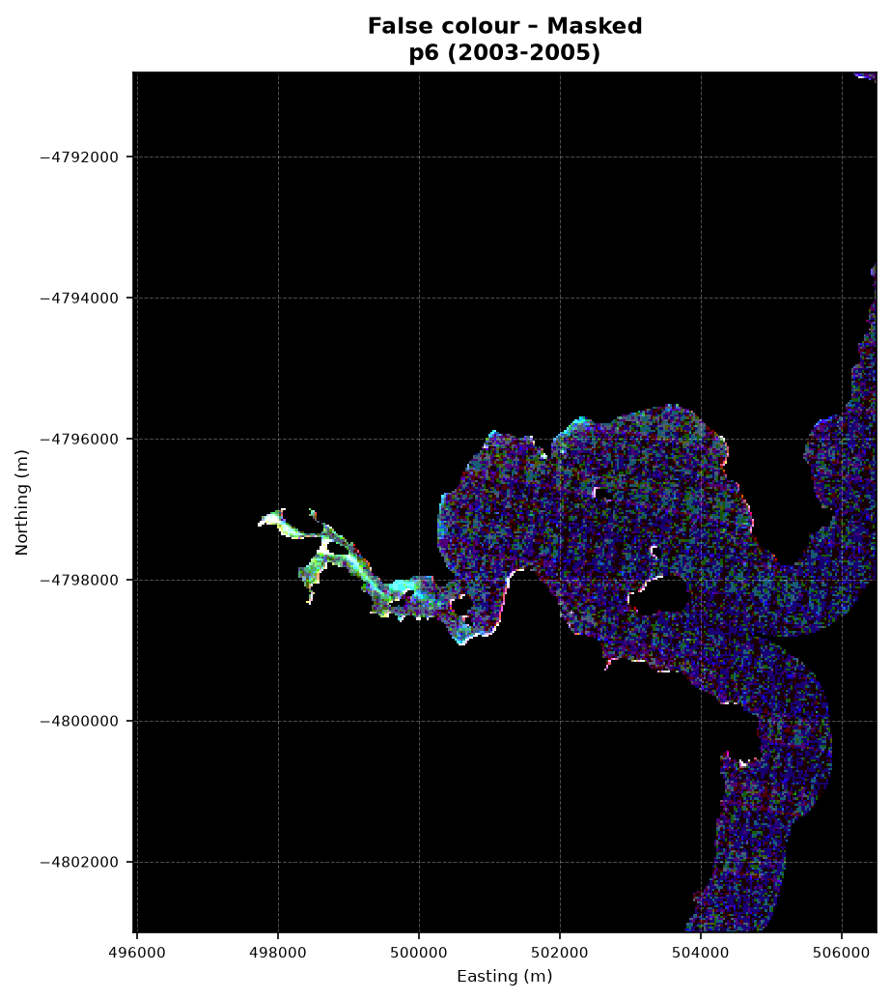

  [ok] p6_2003-2005_false_masked.tif -> false_colour_masked_p6_2003-2005.png


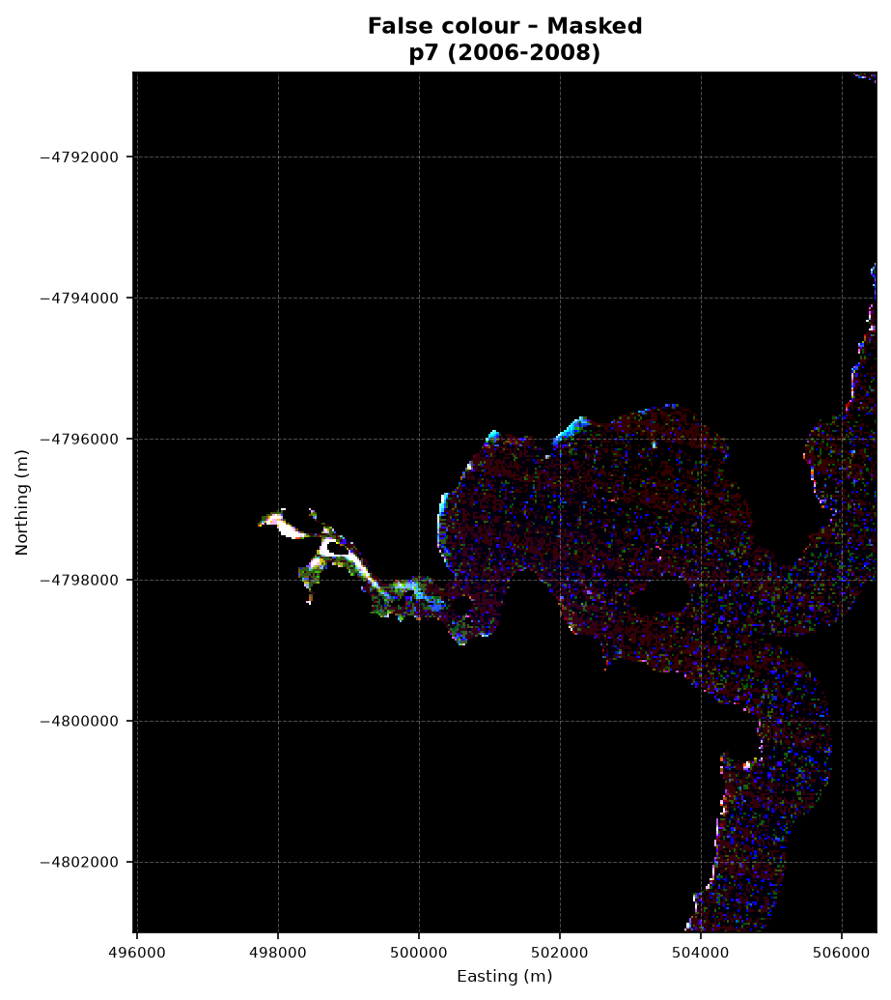

  [ok] p7_2006-2008_false_masked.tif -> false_colour_masked_p7_2006-2008.png


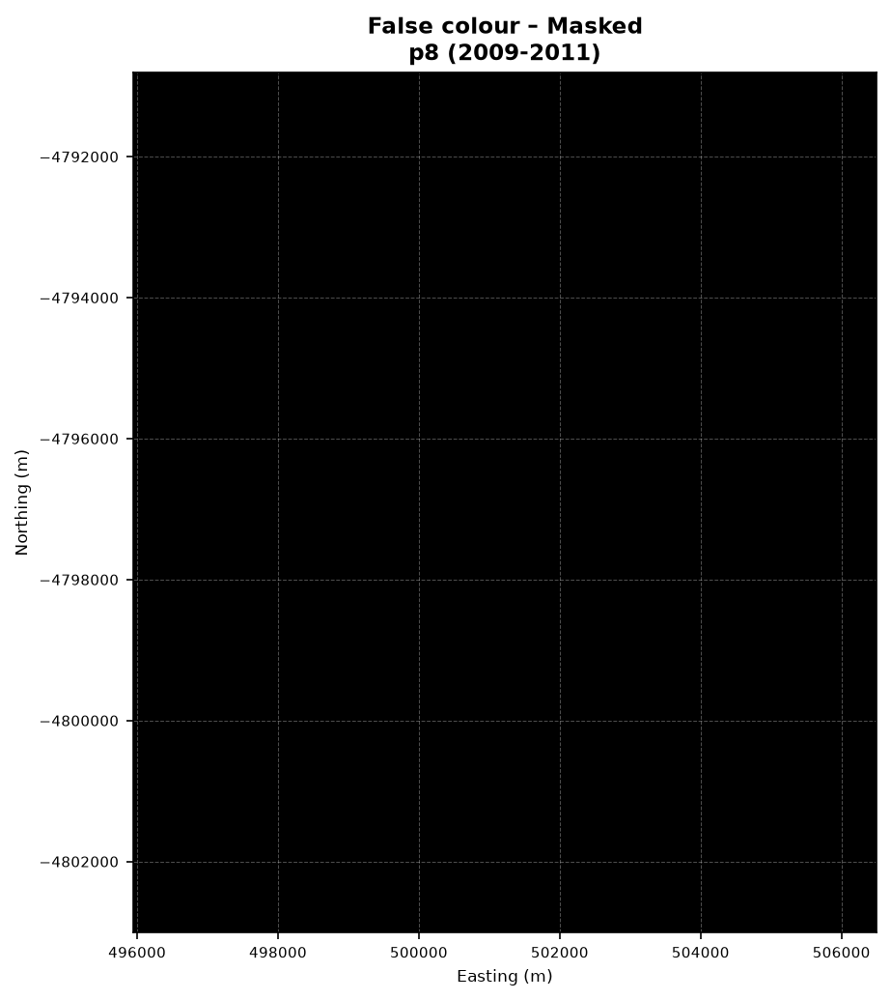

  [ok] p8_2009-2011_false_masked.tif -> false_colour_masked_p8_2009-2011.png


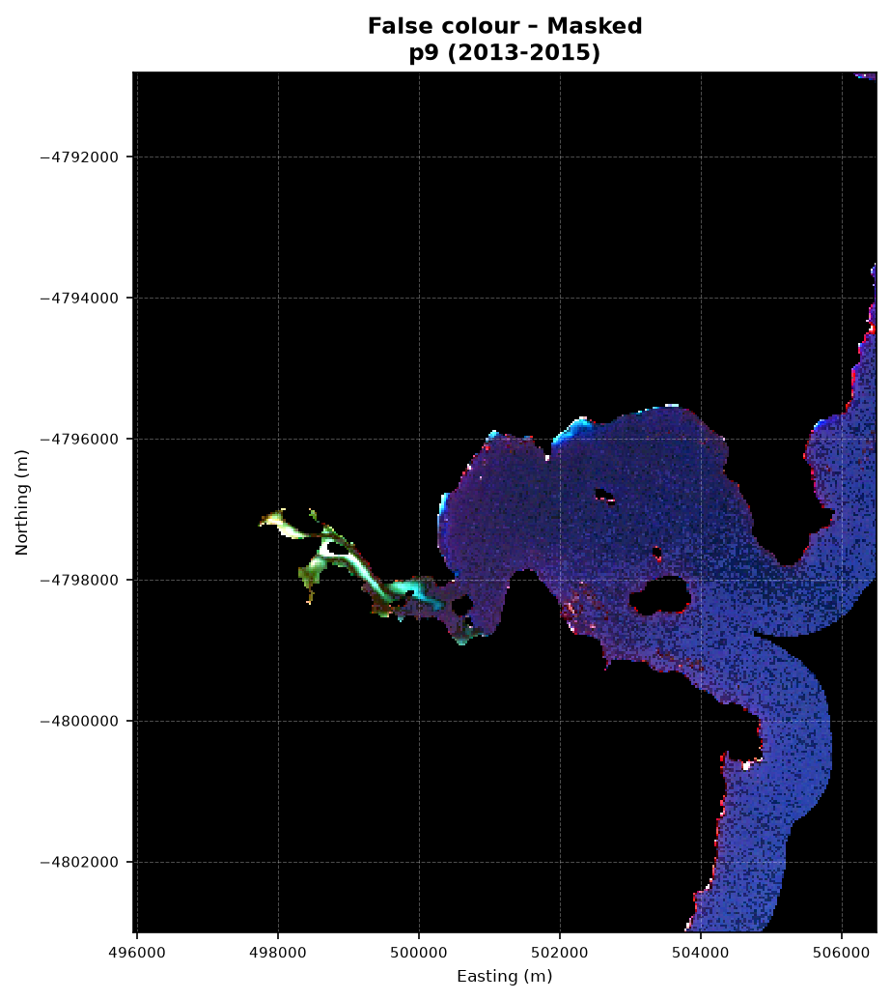

  [ok] p9_2013-2015_false_masked.tif -> false_colour_masked_p9_2013-2015.png


In [4]:
# -------------------------------------------------------
# 4. Main loop — process every file in every image set
# -------------------------------------------------------
# For each of the four sets (true/full, true/masked, false/full,
# false/masked) this:
#   1. finds and sorts all period files (p1..p9)
#   2. crops + stretches each one to Tower Bay
#   3. plots + saves an individual PNG for every mosaic
#   4. builds a 3x3 grid PNG comparing all periods in that set

results = {}  # label -> list of (period, years, rgb_display, extent, file_path)

for label, folder, pattern in IMAGE_SETS:

    files = sorted(folder.glob(pattern), key=period_sort_key)

    if not files:
        print(f"[skip] No files found for '{label}' in {folder}")
        continue

    set_slug = label.lower().replace(" – ", "_").replace(" ", "_")
    set_output_dir = output_dir / set_slug
    set_output_dir.mkdir(parents=True, exist_ok=True)

    processed = []

    print(f"\n=== {label} ({len(files)} files) ===")

    for file_path in files:

        period, years = parse_period(file_path)
        title = f"{label}\n{period} ({years})" if years else f"{label}\n{file_path.stem}"

        try:
            crop, crop_transform = load_and_crop(file_path)
            rgb_display = stretch_to_rgb(crop)
        except Exception as e:
            print(f"  [error] {file_path.name}: {e}")
            continue

        height, width = rgb_display.shape[:2]
        extent = extent_from_transform(crop_transform, height, width)

        # Individual plot
        fig, ax = plt.subplots(figsize=(8, 7), dpi=150)
        plot_mosaic(ax, rgb_display, extent, title)
        plt.tight_layout()

        out_name = f"{set_slug}_{period}_{years}.png".replace("__", "_")
        fig.savefig(set_output_dir / out_name, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        processed.append((period, years, rgb_display, extent, file_path))
        print(f"  [ok] {file_path.name} -> {out_name}")

    results[label] = processed


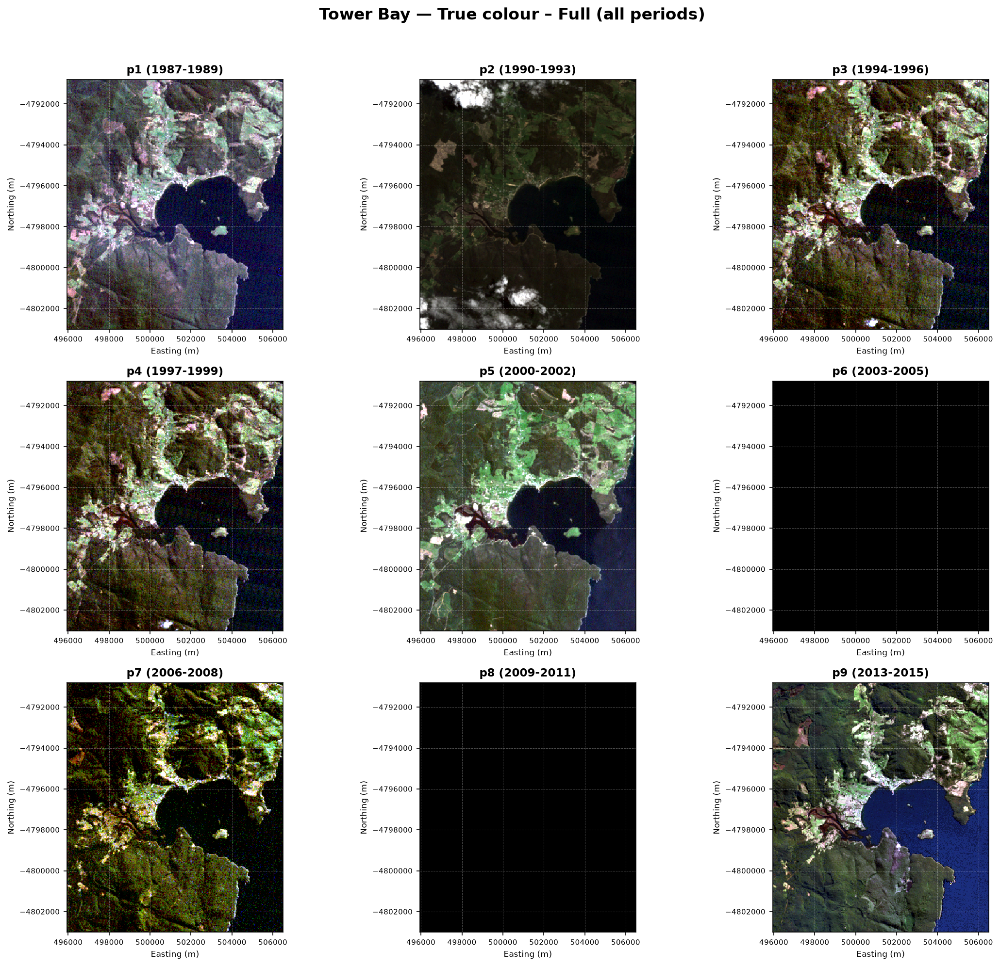

Saved grid: /Users/rameshrawal/Downloads/imagemosaics/outputs/true_colour_full_ALL_PERIODS_grid.png


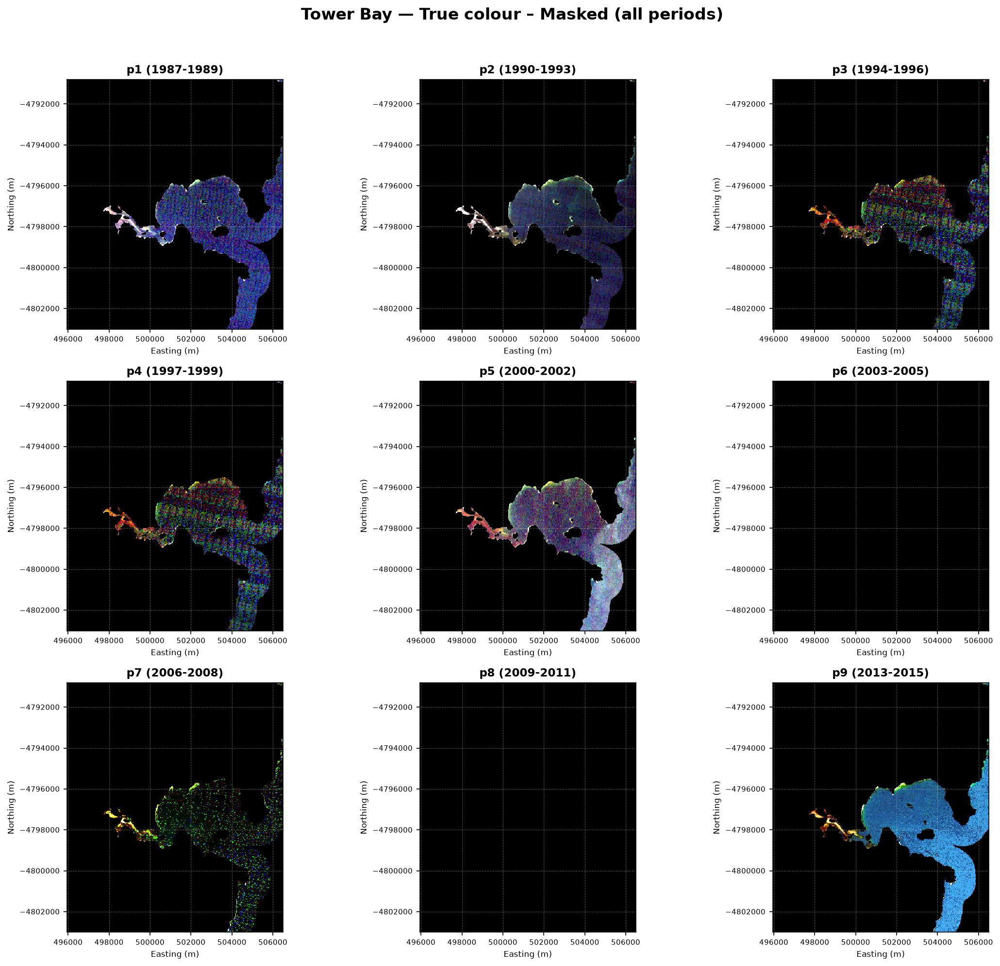

Saved grid: /Users/rameshrawal/Downloads/imagemosaics/outputs/true_colour_masked_ALL_PERIODS_grid.png


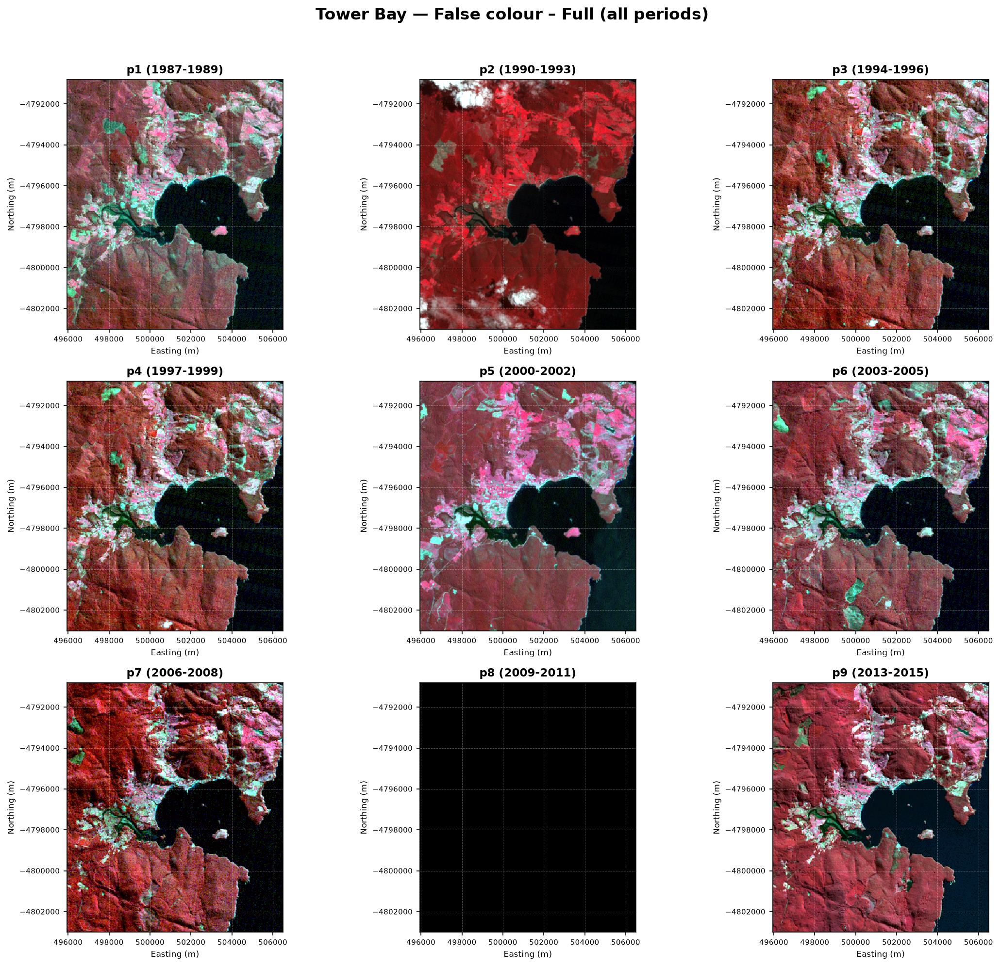

Saved grid: /Users/rameshrawal/Downloads/imagemosaics/outputs/false_colour_full_ALL_PERIODS_grid.png


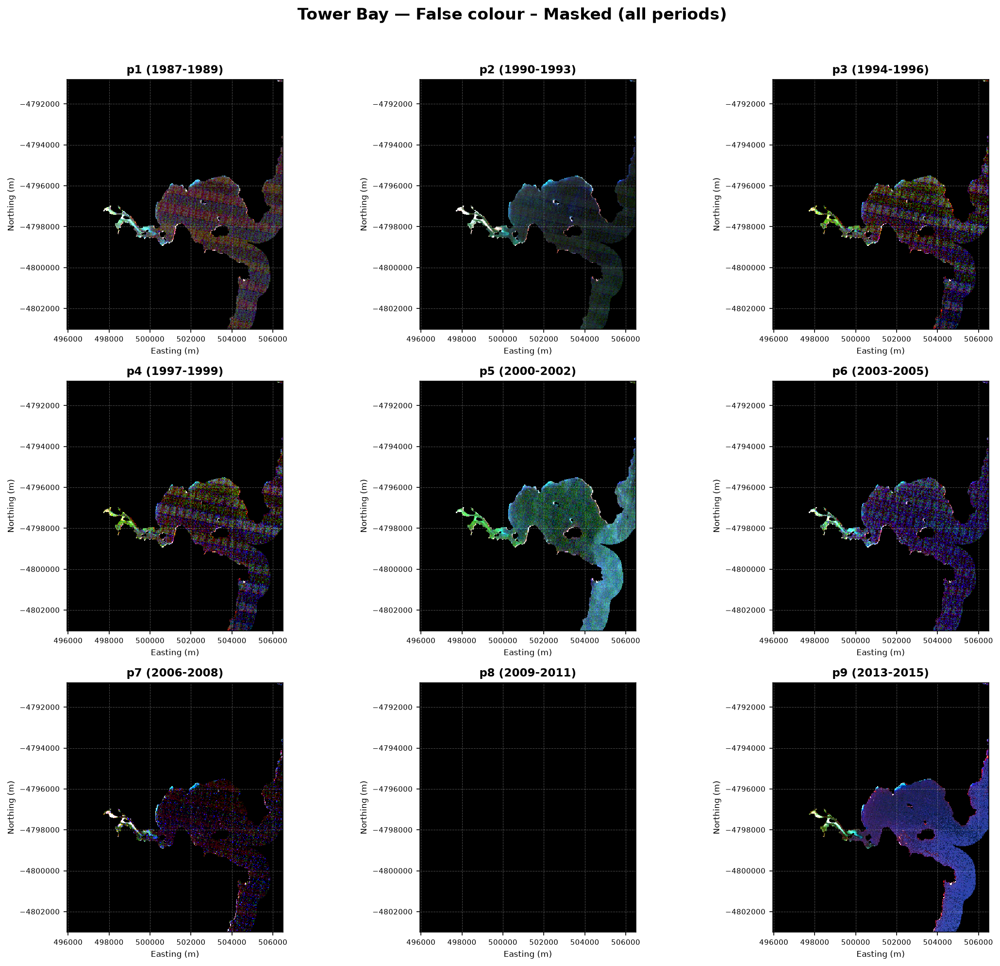

Saved grid: /Users/rameshrawal/Downloads/imagemosaics/outputs/false_colour_masked_ALL_PERIODS_grid.png


In [5]:
# -------------------------------------------------------
# 5. Grid comparison — all periods side by side, per image set
# -------------------------------------------------------

for label, processed in results.items():

    if not processed:
        continue

    n = len(processed)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows), dpi=150)
    axes = np.atleast_1d(axes).ravel()

    for ax, (period, years, rgb_display, extent, file_path) in zip(axes, processed):
        title = f"{period} ({years})" if years else file_path.stem
        plot_mosaic(ax, rgb_display, extent, title)

    # Hide any unused subplot axes
    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(f"Tower Bay — {label} (all periods)", fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    set_slug = label.lower().replace(" – ", "_").replace(" ", "_")
    grid_path = output_dir / f"{set_slug}_ALL_PERIODS_grid.png"
    fig.savefig(grid_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved grid: {grid_path}")


## 6. Key interpretation limitations

1. **30 m pixels are coarse for small farm or aquaculture structures.**  
   A feature only tens of metres wide may occupy one or only a few Landsat pixels.

2. **The mosaics are historical.**  
   They cover the Landsat period represented by the supplied files, ending in 2015.

3. **A mosaic is not a single-date observation.**  
   It combines imagery to provide broader cloud-free spatial coverage.

4. **Displayed colour is not a direct measurement of kelp abundance.**  
   The RGB figures are visual products and have also been contrast-stretched by this notebook.

5. **Masked does not mean kelp-only.**  
   It means a study-area mask has been applied.

6. **Visual inspection alone is insufficient for confirmed kelp detection.**  
   The IMAS study used spectral classification, including NDVI thresholding, to derive giant-kelp canopy extent.

### Practical use for the Tower Bay project

Use these mosaics for:

- historical coastal context;
- broad comparison of the Tower Bay region through time;
- understanding where kelp-suitable coastal zones occur;
- providing a Landsat background layer beneath mapped farm or lease polygons.

For precise modern lease boundaries, cages, lines or other small aquaculture infrastructure, a **higher-resolution contemporary imagery source** is more appropriate.
